# **Amazon Prime Video — Exploratory Data Analysis**



##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Prepared by** — Prajwal Veerendra H


# **Project Summary -**



This project focuses on performing Exploratory Data Analysis (EDA) on Amazon Prime Video content to understand the distribution, characteristics, and patterns within its available movie and television show catalogue. The analysis uses two datasets, titles and credits, to explore content-related information and identify trends that may be useful for understanding the platform's content library.

The analysis begins with examining the structure of the datasets, identifying data types, checking for missing values, and understanding the overall quality of the available information. Data cleaning and preprocessing are important steps because incomplete or inconsistent records can affect the accuracy of the analysis. Relevant columns are selected and prepared to support meaningful comparisons and visualizations.

Several visualizations are used to investigate different aspects of the catalogue, including content types, genres, release years, production countries, age classifications, runtime, and available ratings. These charts help present the data in an understandable format and make it easier to identify patterns, differences, and potential areas of interest. Genre analysis helps describe the types of content represented in the dataset, while release-year analysis shows how catalogue entries are distributed across time. Country-based analysis highlights the geographical representation of available titles. Runtime and rating analysis provide additional perspectives on content characteristics and audience suitability.

The findings can support business decisions related to content categorization, catalogue management, audience targeting, and future content planning. For example, understanding the representation of different genres and countries may help identify areas where further investigation into content availability could be valuable. Similarly, examining release years and ratings can provide context for evaluating the composition of the existing catalogue.

However, the results must be interpreted carefully. The presence of a title does not necessarily indicate its popularity, profitability, viewership, or audience satisfaction. These outcomes would require additional information, such as viewing hours, user engagement, subscription behaviour, and revenue.

Overall, this project demonstrates how EDA and data visualization can transform raw catalogue data into structured insights, helping stakeholders understand the available content and identify opportunities for further analysis and informed decision-making.

# **GitHub Link -**


[Link](https://github.com/Prajwal-VH?tab=repositories)


# **Problem Statement**


Amazon Prime Video's catalogue contains movies and television shows with different genres, release years, production countries, content ratings, and runtime characteristics. Exploring these fields can help describe the variety and structure of the catalogue and identify patterns that merit further investigation.

This project uses Exploratory Data Analysis (EDA) to examine those characteristics and assess data-quality limitations, including missing metadata and numerical values that may have been filled with zero. The available files describe titles and credits, rather than actual viewing or subscription activity, so business outcomes must not be inferred directly from catalogue counts.

#### **Define Your Business Objective?**


The objective is to understand the composition of the Amazon Prime Video catalogue through data preparation, descriptive analysis, and visualisation. Specifically, the project compares movies with TV shows, examines release trends, identifies genres and countries most represented in the catalogue, reviews content-rating and runtime distributions, and explores relationships among IMDb and TMDb measures.

These findings can help frame questions for catalogue planning—for example, where content variety is concentrated or where metadata is incomplete. They cannot establish what audiences prefer or whether a pattern increases subscriptions, retention, or revenue without supporting audience and business data.

To address the objective, I inspected and prepared the title and credits data, reviewed the available columns and missing values, and built visualisations for key catalogue dimensions. The charts compare movie and TV-show representation, release-year counts, genre and production-country distributions, ratings, runtime and seasons, and relationships among selected numerical fields.

Together, these views describe the catalogue and highlight patterns that may warrant further investigation. Any recommendation about content investment should be validated against viewing hours, unique viewers, completion rates, regional subscriptions, retention, licensing costs, and revenue. The catalogue data alone cannot confirm commercial impact.

### Import Libraries


In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import random
from pathlib import Path
import ast

# Calm Focus palette — used consistently across charts
PALETTE = {
    "teal": "#168C8C",
    "coral": "#E88776",
    "slate": "#64748B",
    "gold": "#D6A84F",
    "light_teal": "#8BCBC5",
    "background": "#F5F3EF",
    "text": "#263238",
}
TYPE_PALETTE = {"MOVIE": PALETTE["teal"], "SHOW": PALETTE["coral"]}

sns.set_theme(style="whitegrid", context="notebook", palette=[PALETTE["teal"], PALETTE["coral"], PALETTE["slate"], PALETTE["gold"]])
plt.rcParams.update({
    "figure.facecolor": PALETTE["background"],
    "axes.facecolor": PALETTE["background"],
    "axes.edgecolor": PALETTE["slate"],
    "axes.labelcolor": PALETTE["text"],
    "text.color": PALETTE["text"],
    "xtick.color": PALETTE["text"],
    "ytick.color": PALETTE["text"],
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "figure.dpi": 120,
    "grid.alpha": 0.22,
})

try:
    from wordcloud import WordCloud
except ImportError:
    WordCloud = None


### Dataset Loading


In [2]:
# Load datasets from the notebook folder; Colab paths are also supported.
base_dir = Path.cwd()
titles_path = base_dir / "titles.csv"
credits_path = base_dir / "credits.csv"

if not titles_path.exists() and Path("/content/titles.csv").exists():
    titles_path = Path("/content/titles.csv")
if not credits_path.exists() and Path("/content/credits.csv").exists():
    credits_path = Path("/content/credits.csv")

titles = pd.read_csv(titles_path)
credits = pd.read_csv(credits_path)
print("Titles dataset:", titles.shape)
print("Credits dataset:", credits.shape)

Titles dataset: (9871, 15)
Credits dataset: (124235, 5)


### Dataset Merged


In [3]:
md = pd.merge(titles,credits, on = 'id', how = 'outer')

### Dataset First View


In [4]:
# Dataset First Look
md.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id,name,character,role
0,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,NaN,61,"['western', 'action', 'romance']",['US'],NaN,tt0025440,5.6,1213.0,4.079,4.7,25629.0,John Wayne,Jerry Mason,ACTOR
1,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,NaN,61,"['western', 'action', 'romance']",['US'],NaN,tt0025440,5.6,1213.0,4.079,4.7,578138.0,Barbara Sheldon,Betty Benson,ACTOR
2,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,NaN,61,"['western', 'action', 'romance']",['US'],NaN,tt0025440,5.6,1213.0,4.079,4.7,27356.0,Lloyd Whitlock,Harris,ACTOR
3,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,NaN,61,"['western', 'action', 'romance']",['US'],NaN,tt0025440,5.6,1213.0,4.079,4.7,100231.0,George 'Gabby' Hayes,Jake 'Grandy' Benson,ACTOR
4,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,NaN,61,"['western', 'action', 'romance']",['US'],NaN,tt0025440,5.6,1213.0,4.079,4.7,13327.0,Yakima Canutt,Joe Cole,ACTOR


### Dataset Rows & Columns count


In [5]:
# Dataset Rows & Columns count
md.shape

(125354, 19)

### Dataset Information


In [6]:
# Dataset Info
md.info()

<class 'pandas.DataFrame'>
RangeIndex: 125354 entries, 0 to 125353
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    125354 non-null  str    
 1   title                 125354 non-null  str    
 2   type                  125354 non-null  str    
 3   description           125163 non-null  str    
 4   release_year          125354 non-null  int64  
 5   age_certification     56857 non-null   str    
 6   runtime               125354 non-null  int64  
 7   genres                125354 non-null  str    
 8   production_countries  125354 non-null  str    
 9   seasons               8501 non-null    float64
 10  imdb_id               119978 non-null  str    
 11  imdb_score            118987 non-null  float64
 12  imdb_votes            118957 non-null  float64
 13  tmdb_popularity       124800 non-null  float64
 14  tmdb_score            114263 non-null  float64
 15  person_id  

### Data Description


In [7]:
md.describe()

,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id
count,125354.000000,125354.00000,8501.000000,118987.000000,1.189570e+05,124800.000000,114263.000000,1.243470e+05
mean,1996.374715,95.30792,2.335372,5.970856,2.311206e+04,10.134483,5.993077,4.062528e+05
std,27.758800,30.39349,3.164860,1.243967,8.816389e+04,40.666765,1.322900,5.614483e+05
min,1912.000000,1.00000,1.000000,1.100000,5.000000e+00,0.000011,0.800000,1.000000e+00
25%,1983.000000,82.00000,1.000000,5.200000,2.790000e+02,1.858000,5.300000,3.899600e+04
50%,2009.000000,93.00000,1.000000,6.100000,1.227000e+03,3.864000,6.100000,1.339340e+05
75%,2017.000000,109.00000,2.000000,6.800000,7.039000e+03,8.787000,6.800000,5.711600e+05
max,2022.000000,549.00000,51.000000,9.900000,1.133692e+06,1437.906000,10.000000,2.371153e+06


#### Duplicate Values


In [8]:
# Dataset Duplicate Value Count
# Check for duplicate values
duplicates = md.duplicated(keep=False)

# Count the duplicate values
duplicate_count = duplicates.value_counts()

print(duplicate_count)

False    125130
True        224
Name: count, dtype: int64


### Removing Duplicates


In [9]:
md.drop_duplicates(["id"],keep='first',inplace=True)

### Confirming that the duplicate values are removed


In [10]:
# Check for duplicate values
duplicates = md.duplicated(keep=False)

# Count the duplicate values
duplicate_count = duplicates.value_counts()

print(duplicate_count)

False    9868
Name: count, dtype: int64


In [11]:
md.shape

(9868, 19)

#### Missing Values/Null Values


In [12]:
# Missing Values/Null Values Count
md.isnull().sum()

id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6484
runtime                    0
genres                     0
production_countries       0
seasons                 8511
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2080
person_id               1007
name                    1007
character               1916
role                    1007
dtype: int64

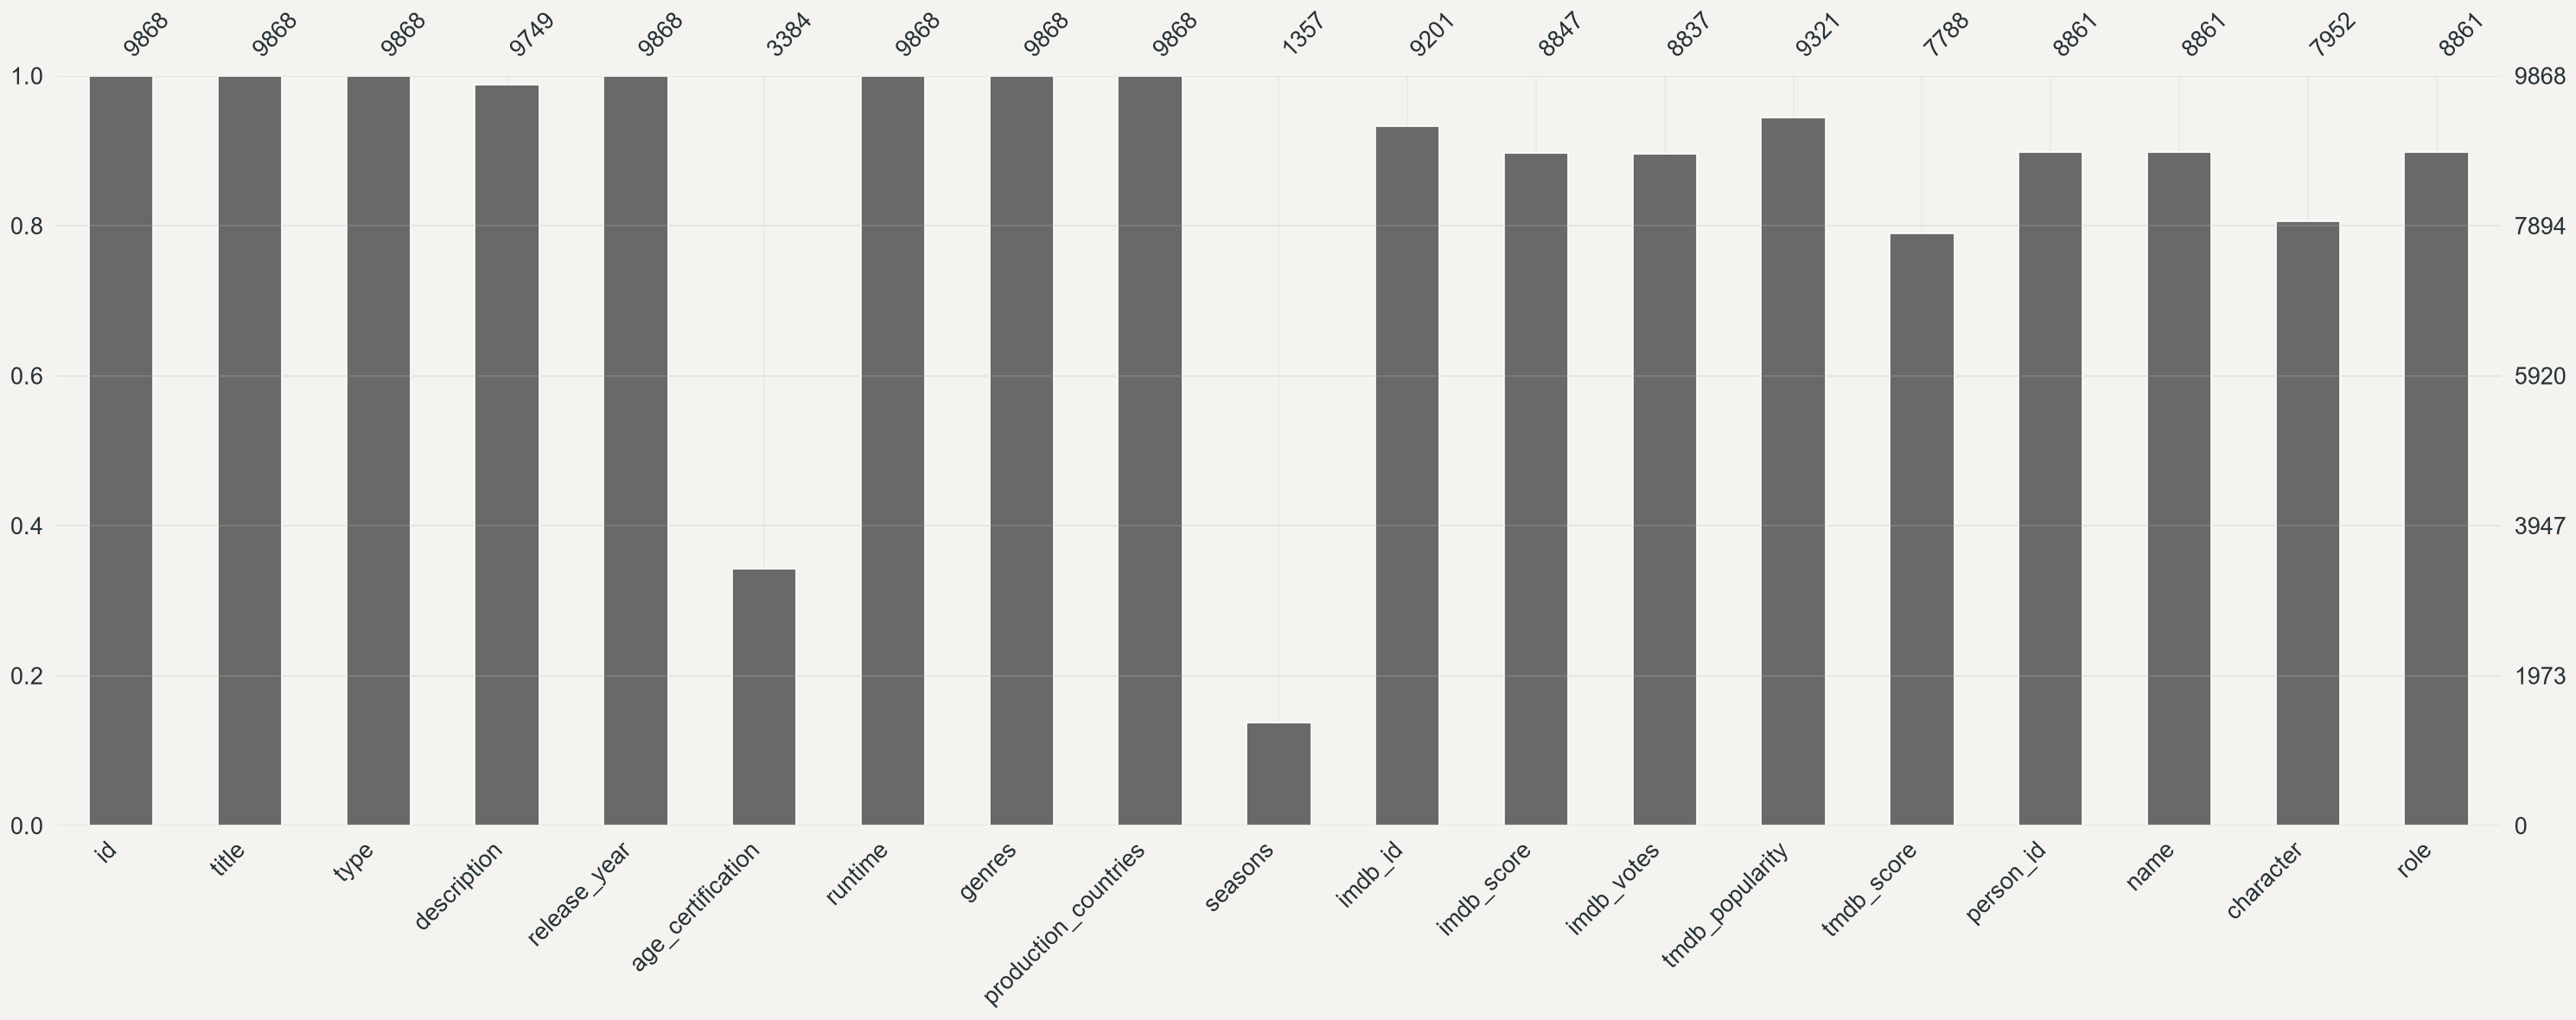

In [13]:
# Visualizing the missing values
import missingno as ms
ms.bar(md)
plt.tight_layout()
plt.show()


### What did you know about your dataset?


**There are total datasets which are:-**
1) titles.csv
2) credits.csv


There are total 15 columns for titles dataset and 5 columns for credits dataset out of which one is common among both dataset which is id column.
There are total 125130 rows before removing duplicates and after removing duplicates, unique values are 9868 rows with total 19 columns after merging both datasets.
The seasons and age_certification has highest and second highest number of null values respectively.
The columns with no null values are id, title, type, release_year, runtime, geners and production_countries.
Description is the second lowest column with null values.


## ***2. Understanding Your Variables***


In [14]:
# Dataset Columns
md.columns

Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score', 'person_id', 'name', 'character', 'role'],
      dtype='str')

In [15]:
# Dataset Describe
md.describe()

,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id
count,9868.000000,9868.000000,1357.000000,8847.000000,8.837000e+03,9321.000000,7788.000000,8.861000e+03
mean,2001.345561,85.979124,2.791452,5.976534,8.536485e+03,6.912168,5.984117,2.921030e+05
std,25.792295,33.515714,4.148958,1.344028,4.592768e+04,30.008727,1.518040,5.016168e+05
min,1912.000000,1.000000,1.000000,1.100000,5.000000e+00,0.000011,0.800000,1.100000e+01
25%,1996.000000,65.000000,1.000000,5.100000,1.180000e+02,1.234000,5.100000,1.982000e+04
50%,2014.000000,89.000000,1.000000,6.100000,4.640000e+02,2.537000,6.000000,6.707600e+04
75%,2018.000000,102.000000,3.000000,6.900000,2.237000e+03,5.640000,6.900000,2.505780e+05
max,2022.000000,549.000000,51.000000,9.900000,1.133692e+06,1437.906000,10.000000,2.367294e+06


### Variables Description


**Title dataset**

1. id-Title ID on JustWatch

2. title Name of the title

3. show_type - TV Show or Movie

4. description - a brief description

5. release year - release year

6. age_certification the age certification

7. runtime-length of an episode in show or length of a movie

8. genres genre of show/movie

9. production countries - Countries that produced the title

10. seasons - No. of seasons if it's a show

11. imdb id The title ID on IMDB

12. imdb_score - IMDB score

13. imdb votes Votes on IMDB

14. tmdb popularity Popularity on IMDB

15. tmdb score - Score on TMDB

**Credits dataset**

1. person_ID - The person ID on JustWatch

2. id title ID on justWatch

3. Name - Actor / Director's name

4. character name The character's name

5. role - Actor / Director


### Check Unique Values for each variable.


In [16]:
# Check Unique Values for each variable.
for x in md.columns:
    print(f"{x} - {md[x].nunique()}")

id - 9868
title - 9737
type - 2
description - 9734
release_year - 110
age_certification - 11
runtime - 207
genres - 2028
production_countries - 497
seasons - 32
imdb_id - 9201
imdb_score - 86
imdb_votes - 3650
tmdb_popularity - 5325
tmdb_score - 89
person_id - 6639
name - 6631
character - 6177
role - 2


In [17]:
md["type"].value_counts()

type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64

In [18]:
md["id"].unique()

<ArrowStringArray>
[ 'tm100001', 'tm1000022', 'tm1000169', 'tm1000186', 'tm1000203', 'tm1000290',
 'tm1000378', 'tm1000406', 'tm1000619',  'tm100065',
 ...
   'ts96439',     'ts968',   'ts97421',   'ts97576',    'ts9770',   'ts98217',
   'ts98222',   'ts98387',   'ts98392',    'ts9913']
Length: 9868, dtype: str

In [19]:
md["title"].unique()

<ArrowStringArray>
[                           'The Lucky Texan',
                'Boonie Bears: The Wild Life',
                                  'Bad Cupid',
                          'Carol's Christmas',
                           'Digging to Death',
                       'Secrets in the Water',
                              'Jathi Ratnalu',
                               'Dark Corners',
                                'Radhe Shyam',
                             'Blind Husbands',
 ...
                           'A Stitch in Time',
                              'Bobby's World',
                                 'Chronofilm',
                             'Volatile Earth',
                   'The Adventures of Tintin',
                                     'Baby u',
          'Music and Sounds with Bonnie Bear',
           'ABC Galaxy: New Space Adventures',
 'Technological Marvels of the Ancient World',
                                 'Crime Inc.']
Length: 9737, dtype: str

In [20]:
md["age_certification"].unique()

<ArrowStringArray>
[    nan,     'R',     'G', 'PG-13',    'PG', 'NC-17',  'TV-G', 'TV-14',
 'TV-Y7',  'TV-Y', 'TV-MA', 'TV-PG']
Length: 12, dtype: str

In [21]:
md["runtime"].unique()

array([ 61,  99,  81,  70,  96,  77, 148,  90, 138,  89,  64,  95, 111,
        63,  84, 146,  65,  45,  71,  62,  75,  55,  83, 139,  87, 100,
        66,  51,  80, 108, 144, 102,  86, 142,  88, 122,  91,  79, 172,
        76,  72, 104,  60, 116,  94,  98, 115, 101, 155,  59, 126, 107,
       110,  69,  53,  33,  74, 124, 119, 132, 152, 136,  85, 151, 105,
        44, 118,  42, 114, 133, 125, 120,  82, 130, 103, 143,  97,  50,
        93, 121,  78, 160,  30, 127, 128, 129,  58, 135, 113,   6,  54,
        47,  92, 112,  52,  56,  73,  23, 157,  57, 134,  49, 109,  32,
       106,  67,  68,  48, 117, 149,  46, 141, 145,  31, 173, 131,  43,
        22, 123,  21, 154, 177, 174, 150,  24,  25, 162, 137,  36,  38,
        16,  40, 164, 328,  28,  41,  39, 185, 158, 182, 163, 180, 140,
       153, 156,  27,  34, 300,  26, 171, 195, 167, 165, 197,  20, 228,
       179, 189, 186, 147, 175, 168, 159, 290, 166,   7, 170,  19, 169,
       194, 178,   1, 181, 161, 193, 540,  10, 216,   2, 176, 18

In [22]:
md["genres"].unique()

<ArrowStringArray>
[                                '['western', 'action', 'romance']',
                                           '['scifi', 'animation']',
                                            '['romance', 'comedy']',
                                            '['drama', 'thriller']',
                                           '['horror', 'thriller']',
                                                     '['thriller']',
                                              '['drama', 'comedy']',
                                             '['romance', 'drama']',
                                             '['drama', 'romance']',
                         '['comedy', 'drama', 'romance', 'action']',
 ...
     '['scifi', 'horror', 'thriller', 'crime', 'drama', 'fantasy']',
                                   '['reality', 'comedy', 'crime']',
                            '['crime', 'documentation', 'romance']',
                       '['drama', 'action', 'thriller', 'romance']',
          

In [23]:
md["production_countries"].unique()

<ArrowStringArray>
[                  '['US']',                   '['CN']',
                       '[]',                   '['IN']',
             '['GB', 'NO']',                   '['CA']',
                   '['IT']',                   '['GB']',
                   '['FR']', '['IT', 'ES', 'DE', 'LI']',
 ...
             '['UY', 'AR']',             '['GB', 'SG']',
       '['CA', 'AU', 'US']',       '['FR', 'CA', 'US']',
             '['KR', 'JP']',                   '['HU']',
             '['CA', 'JP']',       '['IL', 'PH', 'ES']',
             '['EG', 'GB']', '['US', 'BE', 'CA', 'FR']']
Length: 497, dtype: str

In [24]:
md["seasons"].unique()

array([nan,  1.,  2.,  4.,  3.,  8.,  6.,  9.,  5.,  7., 11., 12., 17.,
       22., 10., 15., 26., 13., 19., 42., 24., 33., 35., 28., 49., 21.,
       51., 16., 18., 31., 14., 25., 34.])

In [25]:
md["imdb_id"].unique()

<ArrowStringArray>
[ 'tt0025440', 'tt11654032', 'tt11333938', 'tt13814142',  'tt7752100',
          nan, 'tt11306376',  'tt8391548',  'tt8960382',  'tt0009937',
 ...
  'tt7638682',  'tt0103373',  'tt7275066',  'tt7204306',  'tt0179552',
  'tt6963828',  'tt6963174',  'tt6954612',  'tt6953902',  'tt0938980']
Length: 9202, dtype: str

In [26]:
md["imdb_votes"].unique()

array([ 1213.,   117.,   181., ..., 16378.,  4503., 17859.], shape=(3651,))

In [27]:
md["imdb_score"].unique()

array([5.6, 5.4, 4.4, 2. , 4.5, nan, 7.5, 4. , 6.9, 5.1, 4.7, 4.1, 8. ,
       5.7, 3.5, 6.3, 4.8, 3.3, 7.3, 5.2, 7. , 4.2, 3.8, 7.4, 7.1, 7.8,
       4.3, 6.1, 6.8, 5. , 5.8, 7.9, 4.9, 4.6, 7.2, 6. , 8.1, 6.4, 6.5,
       5.5, 6.7, 8.3, 9.2, 5.9, 5.3, 3. , 2.3, 8.2, 6.6, 1.8, 2.5, 9.1,
       6.2, 8.7, 7.7, 3.7, 3.2, 3.1, 3.9, 2.8, 7.6, 2.7, 2.6, 2.2, 3.4,
       3.6, 8.4, 8.6, 9.3, 2.9, 2.1, 9. , 1.6, 1.7, 1.5, 8.9, 9.9, 9.4,
       8.5, 1.3, 2.4, 1.9, 8.8, 1.2, 1.1, 9.7, 9.5])

In [28]:
md["tmdb_popularity"].unique()

array([ 4.079,  6.135,  3.295, ...,  3.94 ,  7.875, 25.766], shape=(5326,))

In [29]:
md["tmdb_score"].unique()

array([ 4.7,  3.8,  4.8,  nan,  5.8,  7.4,  8. ,  5.4,  6.3,  5. ,  5.6,
        4.4,  8.2,  4.5,  6. ,  5.1,  5.3,  1. ,  6.9,  6.8,  4. ,  6.6,
        5.7,  5.5,  7. ,  6.5,  7.1,  7.5,  9. ,  5.2,  6.7,  4.9,  6.4,
        4.2,  6.2,  7.3,  3.4,  4.3,  7.2,  3. ,  9.1,  8.8,  8.1,  3.7,
        1.8,  3.6,  7.6,  5.9, 10. ,  6.1,  7.9,  3.5,  3.9,  2. ,  2.3,
        2.5,  8.4,  4.6,  7.8,  8.7,  8.5,  2.7,  7.7,  4.1,  8.6,  3.3,
        0.8,  1.5,  3.2,  8.3,  2.9,  2.8,  2.2,  1.7,  3.1,  2.6,  9.8,
        1.4,  2.4,  9.3,  1.9,  1.2,  2.1,  1.3,  9.7,  9.5,  8.9,  9.4,
        9.6,  9.2])

In [30]:
md["person_id"].unique()

array([  25629., 1793831.,    2853., ..., 1992417.,   27664.,  110490.],
      shape=(6640,))

In [31]:
md["name"].unique()

<ArrowStringArray>
[          'John Wayne',          'Chris Boike',     'John Rhys-Davies',
                    nan,          'Ford Austin',       'Cerina Vincent',
    'Naveen Polishetty',        'Sam Hazeldine',              'Prabhas',
   'Erich von Stroheim',
 ...
        'Zack Calderon', 'Lion-Russell Baumann',            'Eva Green',
     'Malina Germanova',       'Richard Coogan',       'Amber Butchart',
           'Gary Owens',         'Joseph Hypes',         'Mark Bazeley',
      'Thierry Wermuth']
Length: 6632, dtype: str

In [32]:
md["character"].unique()

<ArrowStringArray>
[           'Jerry Mason',                      nan,                 'Archie',
          'David Vanowen',                  'Laura',       'Jogipet Srikanth',
               'Strachan',           'Vikramaditya',  'Lt. Erich von Steuben',
 'Lt. Tom 'Soapy' Cooper',
 ...
              'Zhen Huan',       'Thorfinn (voice)',           'Xiao Yi Qing',
           'Bette Porter',           'Brooke Logan',           'Jia Malhotra',
         'Luca Nicolakis',            'Lydia Wells',  'Marshal Matthew Wayne',
         'Tintin (voice)']
Length: 6178, dtype: str

In [33]:
md["role"].unique()

<ArrowStringArray>
['ACTOR', nan, 'DIRECTOR']
Length: 3, dtype: str

## 3. ***Data Wrangling***


### Data Wrangling Code


In [34]:
# Write your code to make your dataset analysis ready.
md[["type","seasons"]][md.type=='SHOW'].isna().sum()

type       0
seasons    0
dtype: int64

In [35]:
md[["type","seasons"]][md.type=='MOVIE'].isna().sum()

type          0
seasons    8511
dtype: int64

In [36]:
# filling up the seasons column which have null values with value 0
md.fillna({'seasons': 0},inplace=True)

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id,name,character,role
0,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,NaN,61,"['western', 'action', 'romance']",['US'],0.0,tt0025440,5.6,1213.0,4.079,4.7,25629.0,John Wayne,Jerry Mason,ACTOR
14,tm1000022,Boonie Bears: The Wild Life,MOVIE,Bear brothers Briar and Bramble set off on an ...,2021,NaN,99,"['scifi', 'animation']",['CN'],0.0,tt11654032,5.4,117.0,6.135,3.8,1793831.0,Chris Boike,NaN,ACTOR
19,tm1000169,Bad Cupid,MOVIE,Archie is a God on a mission to ensure that tr...,2021,NaN,81,"['romance', 'comedy']",[],0.0,tt11333938,4.4,181.0,3.295,4.8,2853.0,John Rhys-Davies,Archie,ACTOR
28,tm1000186,Carol's Christmas,MOVIE,Scrooge encounters the ghost of her late busin...,2021,NaN,70,"['drama', 'thriller']",[],0.0,tt13814142,2.0,48.0,0.600,NaN,NaN,NaN,NaN,NaN
29,tm1000203,Digging to Death,MOVIE,David Van Owen moves into a mysterious house a...,2021,NaN,96,"['horror', 'thriller']",['US'],0.0,tt7752100,4.5,464.0,3.543,5.8,67535.0,Ford Austin,David Vanowen,ACTOR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125349,ts98217,Baby u,SHOW,Class is in session! Join BabyU for all the ba...,2011,TV-Y,24,[],['US'],1.0,tt6963828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125350,ts98222,Music and Sounds with Bonnie Bear,SHOW,"Together with her best friend, Mr. Gramophone,...",2006,TV-Y,26,[],[],1.0,tt6963174,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125351,ts98387,ABC Galaxy: New Space Adventures,SHOW,Meet Giggs and Hugg - two adorable friends tha...,2015,TV-G,13,[],[],1.0,tt6954612,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125352,ts98392,Technological Marvels of the Ancient World,SHOW,Impossible discoveries have been made. Some of...,2005,TV-G,79,['history'],[],1.0,tt6953902,7.8,10.0,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
md.fillna({'description': 'Not Available'},inplace=True)

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id,name,character,role
0,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,NaN,61,"['western', 'action', 'romance']",['US'],0.0,tt0025440,5.6,1213.0,4.079,4.7,25629.0,John Wayne,Jerry Mason,ACTOR
14,tm1000022,Boonie Bears: The Wild Life,MOVIE,Bear brothers Briar and Bramble set off on an ...,2021,NaN,99,"['scifi', 'animation']",['CN'],0.0,tt11654032,5.4,117.0,6.135,3.8,1793831.0,Chris Boike,NaN,ACTOR
19,tm1000169,Bad Cupid,MOVIE,Archie is a God on a mission to ensure that tr...,2021,NaN,81,"['romance', 'comedy']",[],0.0,tt11333938,4.4,181.0,3.295,4.8,2853.0,John Rhys-Davies,Archie,ACTOR
28,tm1000186,Carol's Christmas,MOVIE,Scrooge encounters the ghost of her late busin...,2021,NaN,70,"['drama', 'thriller']",[],0.0,tt13814142,2.0,48.0,0.600,NaN,NaN,NaN,NaN,NaN
29,tm1000203,Digging to Death,MOVIE,David Van Owen moves into a mysterious house a...,2021,NaN,96,"['horror', 'thriller']",['US'],0.0,tt7752100,4.5,464.0,3.543,5.8,67535.0,Ford Austin,David Vanowen,ACTOR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125349,ts98217,Baby u,SHOW,Class is in session! Join BabyU for all the ba...,2011,TV-Y,24,[],['US'],1.0,tt6963828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125350,ts98222,Music and Sounds with Bonnie Bear,SHOW,"Together with her best friend, Mr. Gramophone,...",2006,TV-Y,26,[],[],1.0,tt6963174,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125351,ts98387,ABC Galaxy: New Space Adventures,SHOW,Meet Giggs and Hugg - two adorable friends tha...,2015,TV-G,13,[],[],1.0,tt6954612,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125352,ts98392,Technological Marvels of the Ancient World,SHOW,Impossible discoveries have been made. Some of...,2005,TV-G,79,['history'],[],1.0,tt6953902,7.8,10.0,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
md.fillna({'age_certification': 'Not Available'},inplace=True)

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id,name,character,role
0,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,Not Available,61,"['western', 'action', 'romance']",['US'],0.0,tt0025440,5.6,1213.0,4.079,4.7,25629.0,John Wayne,Jerry Mason,ACTOR
14,tm1000022,Boonie Bears: The Wild Life,MOVIE,Bear brothers Briar and Bramble set off on an ...,2021,Not Available,99,"['scifi', 'animation']",['CN'],0.0,tt11654032,5.4,117.0,6.135,3.8,1793831.0,Chris Boike,NaN,ACTOR
19,tm1000169,Bad Cupid,MOVIE,Archie is a God on a mission to ensure that tr...,2021,Not Available,81,"['romance', 'comedy']",[],0.0,tt11333938,4.4,181.0,3.295,4.8,2853.0,John Rhys-Davies,Archie,ACTOR
28,tm1000186,Carol's Christmas,MOVIE,Scrooge encounters the ghost of her late busin...,2021,Not Available,70,"['drama', 'thriller']",[],0.0,tt13814142,2.0,48.0,0.600,NaN,NaN,NaN,NaN,NaN
29,tm1000203,Digging to Death,MOVIE,David Van Owen moves into a mysterious house a...,2021,Not Available,96,"['horror', 'thriller']",['US'],0.0,tt7752100,4.5,464.0,3.543,5.8,67535.0,Ford Austin,David Vanowen,ACTOR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125349,ts98217,Baby u,SHOW,Class is in session! Join BabyU for all the ba...,2011,TV-Y,24,[],['US'],1.0,tt6963828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125350,ts98222,Music and Sounds with Bonnie Bear,SHOW,"Together with her best friend, Mr. Gramophone,...",2006,TV-Y,26,[],[],1.0,tt6963174,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125351,ts98387,ABC Galaxy: New Space Adventures,SHOW,Meet Giggs and Hugg - two adorable friends tha...,2015,TV-G,13,[],[],1.0,tt6954612,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125352,ts98392,Technological Marvels of the Ancient World,SHOW,Impossible discoveries have been made. Some of...,2005,TV-G,79,['history'],[],1.0,tt6953902,7.8,10.0,NaN,NaN,NaN,NaN,NaN,NaN


In [39]:
md.fillna({'imdb_id': 'unavailable'},inplace=True)

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id,name,character,role
0,tm100001,The Lucky Texan,MOVIE,"Jerry Mason, a young Texan, and Jake Benson, a...",1934,Not Available,61,"['western', 'action', 'romance']",['US'],0.0,tt0025440,5.6,1213.0,4.079,4.7,25629.0,John Wayne,Jerry Mason,ACTOR
14,tm1000022,Boonie Bears: The Wild Life,MOVIE,Bear brothers Briar and Bramble set off on an ...,2021,Not Available,99,"['scifi', 'animation']",['CN'],0.0,tt11654032,5.4,117.0,6.135,3.8,1793831.0,Chris Boike,NaN,ACTOR
19,tm1000169,Bad Cupid,MOVIE,Archie is a God on a mission to ensure that tr...,2021,Not Available,81,"['romance', 'comedy']",[],0.0,tt11333938,4.4,181.0,3.295,4.8,2853.0,John Rhys-Davies,Archie,ACTOR
28,tm1000186,Carol's Christmas,MOVIE,Scrooge encounters the ghost of her late busin...,2021,Not Available,70,"['drama', 'thriller']",[],0.0,tt13814142,2.0,48.0,0.600,NaN,NaN,NaN,NaN,NaN
29,tm1000203,Digging to Death,MOVIE,David Van Owen moves into a mysterious house a...,2021,Not Available,96,"['horror', 'thriller']",['US'],0.0,tt7752100,4.5,464.0,3.543,5.8,67535.0,Ford Austin,David Vanowen,ACTOR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125349,ts98217,Baby u,SHOW,Class is in session! Join BabyU for all the ba...,2011,TV-Y,24,[],['US'],1.0,tt6963828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125350,ts98222,Music and Sounds with Bonnie Bear,SHOW,"Together with her best friend, Mr. Gramophone,...",2006,TV-Y,26,[],[],1.0,tt6963174,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125351,ts98387,ABC Galaxy: New Space Adventures,SHOW,Meet Giggs and Hugg - two adorable friends tha...,2015,TV-G,13,[],[],1.0,tt6954612,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
125352,ts98392,Technological Marvels of the Ancient World,SHOW,Impossible discoveries have been made. Some of...,2005,TV-G,79,['history'],[],1.0,tt6953902,7.8,10.0,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
# Fill missing values only in text columns
text_cols = md.select_dtypes(
    include=['object', 'string']
).columns

md[text_cols] = md[text_cols].fillna('Unknown')

In [41]:
md.drop_duplicates(inplace=True)

In [42]:
md["genres"]=md["genres"].apply(ast.literal_eval)
md["production_countries"]=md["production_countries"].apply(ast.literal_eval)

In [43]:
mdu=md.explode("genres").explode("production_countries").reset_index(drop=True)

In [44]:
mdu.shape

(25819, 19)

In [45]:
mdu.fillna("unavailable",inplace=True)

TypeError: Invalid value 'unavailable' for dtype 'float64'

In [ ]:
mdu.isna().sum()

In [ ]:
mdu.duplicated().sum()

In [ ]:
mdu.production_countries=mdu.production_countries.replace("United State of America","US")
mdu.production_countries=mdu.production_countries.replace("XX","unavailable")

In [ ]:
#Dictionary mapping country codes to country names

country_mapping = {'SU': 'Soviet Union', 'Unavailable': 'Unknown', 'IN': 'India', 'IT': 'Italy', 'JP': 'Japan', 'FR': 'France', 'HK': 'Hong Kong', 'ES': 'Spain', 'IL': 'Israel', 'AU': 'Australia',

'CH': 'Switzerland', 'IE': 'Ireland', 'GR': 'Greece', 'CN': 'China', 'PH': 'Philippines', 'NL': 'Netherlands', 'YU': 'Yugoslavia', 'CI': 'Ivory Coast (Côte d Ivoire)' , 'PR': 'Puerto Rico', 'LI': 'Liechtenstein',

'US': 'United States', 'GB': 'United Kingdom', 'MX': 'Mexico', 'CA': 'Canada', 'DE': 'Germany', 'ZA': 'South Africa', 'PT': 'Portugal', 'CL': 'Chile', 'SE': 'Sweden', 'BR': 'Brazil', 'DK': 'Denmark', 'NZ': 'New Zealand', 'RU': 'Russia', 'LU': 'Luxembourg', 'CZ': 'Czech Republic', 'FI': 'Finland', 'AT': 'Austria', 'SK': 'Slovakia', 'AR': 'Argentina', 'VE': 'Venezuela', 'TH': 'Thailand', 'PL': 'Poland', 'AE': 'United Arab Emirates', 'SI': 'Slovenia', 'BA': 'Bosnia and Herzegovina', 'ID': 'Indonesia', 'NO': 'Norway', 'AF': 'Afghanistan', 'IR': 'Iran', 'IS': 'Iceland', 'BG': 'Bulgaria', 'JM': 'Jamaica', 'RS': 'Serbia', 'SZ': 'Eswatini (Swaziland)', 'LT': 'Lithuania', 'TC': 'Turks and Caicos Islands',

'KR': 'South Korea', 'XC': 'Czechoslovakia', 'HU': 'Hungary', 'TW': 'Taiwan', 'AN': 'Netherlands Antilles', 'MC': 'Monaco', 'CO': 'Colombia', 'RO': 'Romania', 'EG': 'Egypt', 'TR': 'Turkey', 'BE': 'Belgium',

'SG': 'Singapore', 'UY': 'Uruguay', 'BO': 'Bolivia', 'UA': 'Ukraine', 'MY': 'Malaysia', 'TN': 'Tunisia','QA': 'Qatar', 'NG': 'Nigeria', 'KZ': 'Kazakhstan', 'GQ': 'Equatorial Guinea', 'MT': 'Malta', 'SO': 'Somalia', 'KE': 'Kenya', 'MA': 'Morocco', 'VN': 'Vietnam', 'BD': 'Bangladesh', 'FJ': 'Fiji', 'MN': 'Mongolia', 'UG': 'Uganda', 'TT': 'Trinidad and Tobago', 'PK': 'Pakistan', 'XK': 'Kosovo', 'PE': 'Peru', 'DO': 'Dominican Republic', 'SV': 'El Salvador', 'GE': 'Georgia', 'PS': 'Palestine', 'HR': 'Croatia', 'LV': 'Latvia', 'AQ': 'Antarctica', 'LB': 'Lebanon', 'KH': 'Cambodia', 'CR': 'Costa Rica', 'BM': 'Bermuda', '30': 'Jordan', 'PA': "Panama", 'AL' : 'Albania', 'CY' : 'Cyprus', 'CU' : 'Cuba', 'PY' : 'Paraguay', 'EE': 'Estonia', 'ET': 'Ethiopia', 'PF': 'French Polynesia', 'EC': 'Ecuador', '10': 'British Indian Ocean Territory', 'AM': 'Armenia',

'SY': 'Syria', 'CM': 'Cameroon', 'LY': 'Libya' }

mdu.production_countries = mdu.production_countries.replace(country_mapping)

In [ ]:
mdu.production_countries.unique()

### What all manipulations have you done and insights you found?


The seasons field is not applicable to movies, so its missing values can be treated differently from missing metadata for shows. Missing age certification, descriptions, and IMDb IDs were labelled as unavailable in the original workflow. Some numerical rating and popularity fields were filled with zero; this can affect averages, correlations, and plots because a zero may represent missing information rather than a genuine score. Genre and production-country fields were expanded into individual category entries for category-level comparisons. Since a title may have multiple genres or production countries, category totals can count the same title more than once. Interpret the resulting patterns with these limitations in mind.

### Personalized chart style — Calm Focus

All charts use a consistent teal, coral, slate, and muted-gold palette, larger figure sizes, clearer titles, softer gridlines, and consistent typography. The styling is designed to make comparisons easier while keeping the notebook visually distinct.

**Interpretation rule:** title/genre/country counts describe catalogue representation, not audience preference, watch time, or subscription growth. Ratings and popularity scores are third-party metadata and should be interpreted with their missing-value limitations in mind.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***


#### Chart - 1


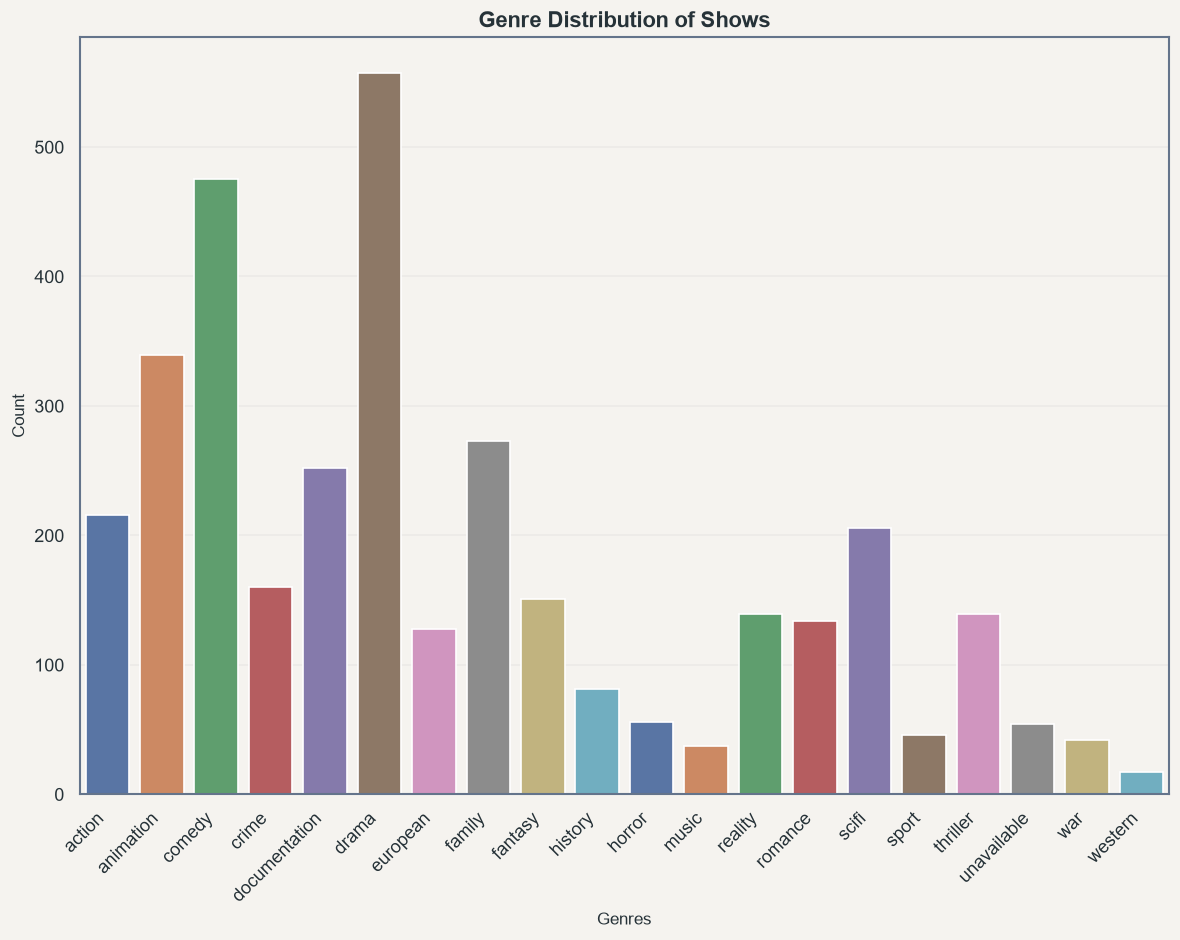

In [46]:
# Chart - 1 visualization code
# Chart - 1 visualization code
# Barplot on genres - shows
genre_plot = mdu[mdu.type=='SHOW'].groupby('genres')['genres'].count()
genre_pl = pd.DataFrame(genre_plot)
# Rename the count column
genre_pl.rename(columns={'genres': 'count'}, inplace=True)
genre_pl.reset_index(inplace=True)
# Create a bar plot
plt.figure(figsize=(10, 8))  # Adjust figure size
sns.barplot(data=genre_pl, x="genres", y="count", hue="genres", palette="deep", legend=False)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha="right")
plt.xlabel("Genres")
plt.ylabel("Count")
plt.title("Genre Distribution of Shows")

# Show the plot
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


This chart was selected to have an idea about the distribution of genres based on shows present.


##### 2. What is/are the insight(s) found from the chart?


Majority of shows belong to the drama genre, with second highest being comedy. There are more than 300 animated shows. There are more than 200 shows belonging to the genre action, documentation, family and scifi. There are over 100 crime, european, fantasy, reality and romance shows. Rest of the genres have very less count with western being least.


##### 3. Will the gained insights help create a positive business impact?



The genre breakdown can support catalogue planning by showing which genres are most represented among TV shows and where the catalogue has comparatively fewer titles. This is useful for identifying areas to investigate, but genre counts alone do not prove which genres viewers prefer or which additions would be profitable.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

A low count for a genre such as western may indicate a narrower selection in the catalogue, but it is not evidence of negative business growth. A potential risk would arise only if viewing and customer research showed unmet demand in underrepresented genres. Viewer engagement and cost data would be needed before changing investment.

#### Chart - 2


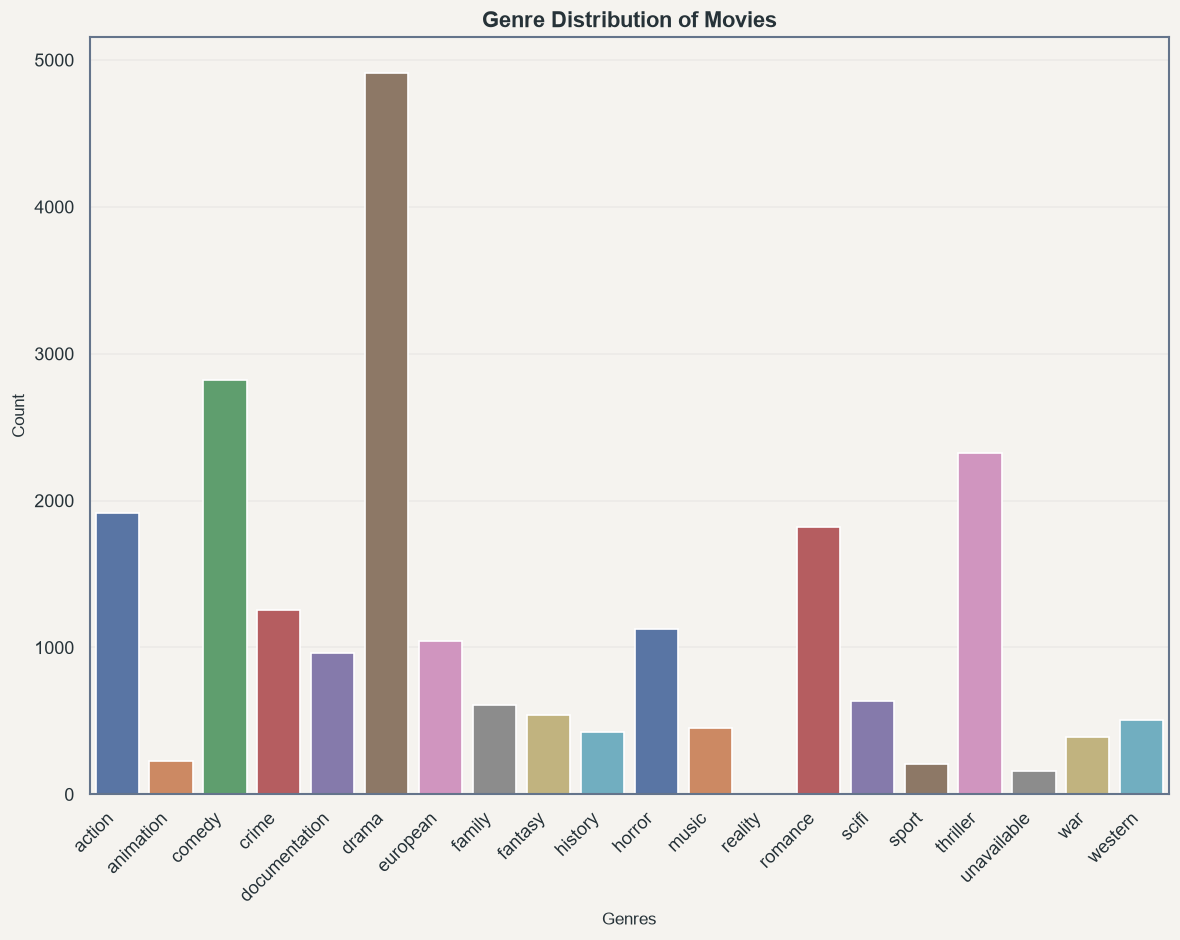

In [47]:
# Chart - 2 visualization code
# Barplot on genres - movies
genre_plot = mdu[mdu.type=='MOVIE'].groupby('genres')['genres'].count()
genre_pl = pd.DataFrame(genre_plot)
# Rename the count column
genre_pl.rename(columns={'genres': 'count'}, inplace=True)
genre_pl.reset_index(inplace=True)
# Create a bar plot
plt.figure(figsize=(10, 8))  # Adjust figure size
sns.barplot(data=genre_pl, x="genres", y="count", hue="genres", palette="deep", legend=False)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha="right")
plt.xlabel("Genres")
plt.ylabel("Count")
plt.title("Genre Distribution of Movies")

# Show the plot
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


This chart was selected to have an idea about the distribution of genres based on movies present.


##### 2. What is/are the insight(s) found from the chart?


Majority of the movies are of the genre drama with comedy being second highest likewise in shows. There are more than 2000 thriller movies. There are around 2000 movies belonging to action and romance genre. There are around 1000 movies that are crime-based. Rest of the genres are quite less with reality being the least.


##### 3. Will the gained insights help create a positive business impact?



The movie genre distribution helps describe the catalogue's strengths and gaps. It can guide further analysis of whether the current mix is balanced with the audience segments the service aims to serve, once actual viewing data is available.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

Genres with fewer listed movies may represent a catalogue gap, but low representation does not automatically mean poor performance or declining subscriptions. The risk should be assessed using genre-level views, completion rates, customer feedback, and acquisition costs rather than counts alone.

#### Chart - 3


In [48]:
mdup = mdu.drop(['genres','production_countries'],axis=1)
mdup.duplicated().sum()

np.int64(15951)

In [49]:
md2 = md.drop(['genres','production_countries'],axis=1)
md2.duplicated().sum()

np.int64(0)

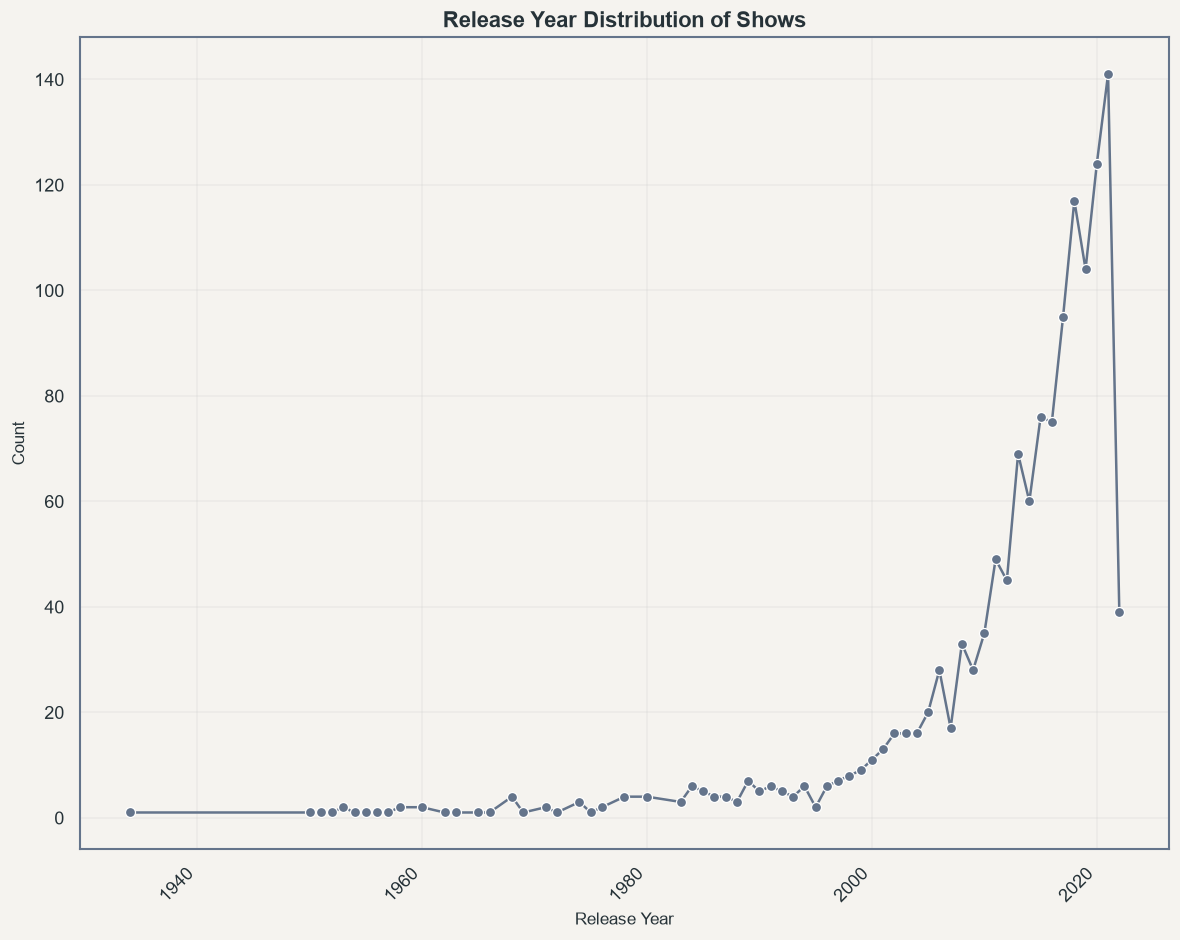

In [50]:
# Chart - 3 visualization code
# No. of shows released in each year

md3 = md2[md2.type=='SHOW']
md4 = md3.groupby('release_year')['release_year'].count()
md4 = pd.DataFrame(md4)
# Rename the count column
md4.rename(columns={'release_year': 'count'}, inplace=True)
md4.reset_index(inplace=True)
# Adjust figure size
plt.figure(figsize=(10, 8))
sns.lineplot(data=md4, x="release_year", y="count", marker="o", color=PALETTE["slate"])
# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha="right")
plt.xlabel("Release Year")
plt.ylabel("Count")
plt.title("Release Year Distribution of Shows")
# Show the plot
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To examine the distribution of no. of shows released each year on Amazon Prime.


##### 2. What is/are the insight(s) found from the chart?


Before 2000, the no. of TV shows released in Prime were less, in fact less than 20. This is due to the fact that there was limited technology at that time. However, after 2000, there is a sharp increase in no. of shows. This was possible due to the advancement in technology, invention of smart phones and internet availability there enabling streaming in platforms. However in 2021, there is a sharp decrease from 140 to 60.


##### 3. Will the gained insights help create a positive business impact?



Release-year counts show how the number of TV-show titles in the dataset changes over time. This can help the business review catalogue growth and investigate whether the mix of older and newer shows aligns with its content strategy.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

The chart shows a drop in the number of listed shows in 2021 compared with 2020. This is a signal to investigate, not proof of negative business growth: the dataset may be incomplete for recent years, and release counts do not measure removals, viewership, or subscriptions. Check data coverage and catalogue additions/removals before drawing conclusions.

#### Chart - 4


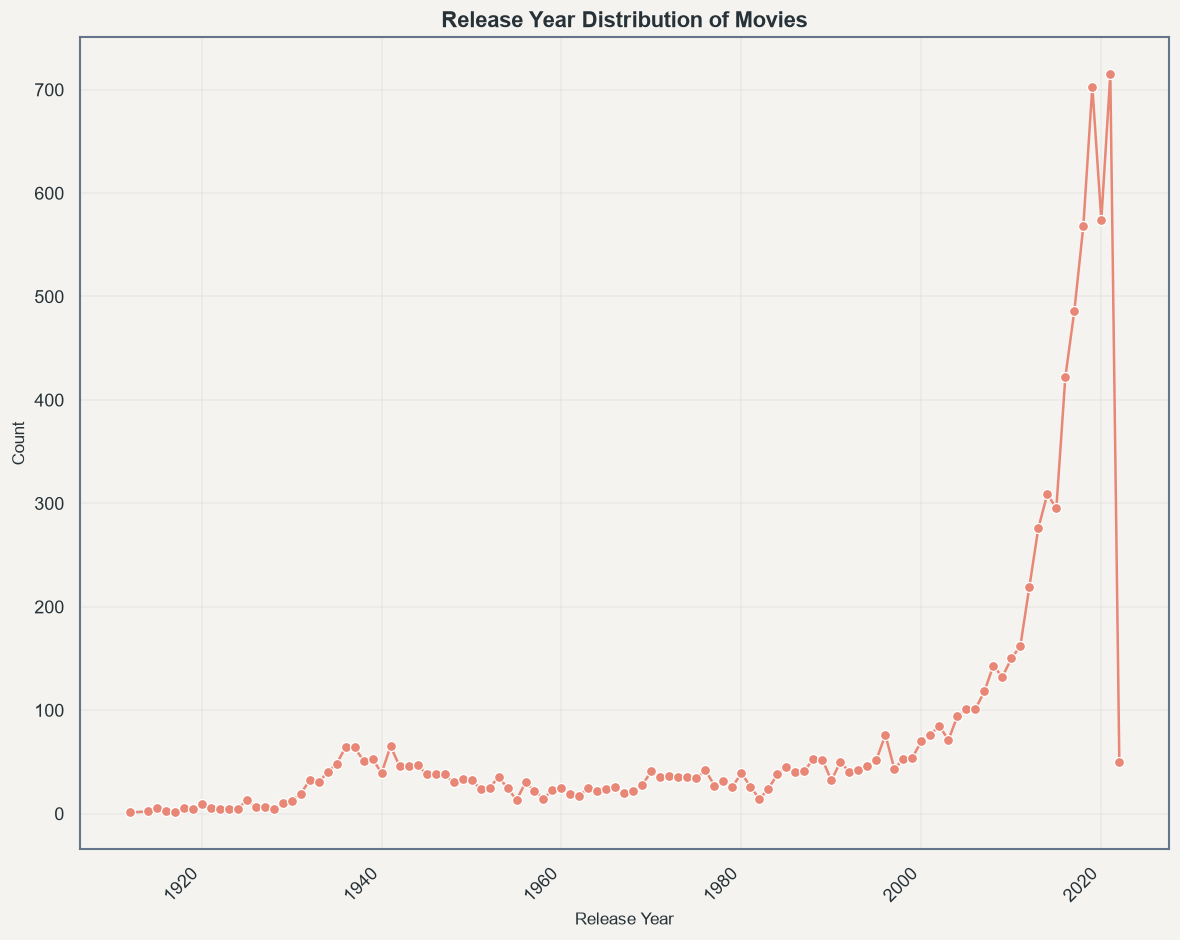

In [51]:
# Chart - 4 visualization code
# Chart - 4 visualization code
# No. of movies released in each year
md5 = md2[md2.type=='MOVIE']
md6 = md5.groupby('release_year')['release_year'].count()
md6 = pd.DataFrame(md6)
# Rename the count column
md6.rename(columns={'release_year': 'count'}, inplace=True)
md6.reset_index(inplace=True)
plt.figure(figsize=(10, 8))  # Adjust figure size
sns.lineplot(data=md6, x="release_year", y="count", marker="o", color=PALETTE["coral"])
# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha="right")
plt.xlabel("Release Year")
plt.ylabel("Count")
plt.title("Release Year Distribution of Movies")
# Show the plot
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To examine the distribution of no. of movies released each year on Amazon Prime.


##### 2. What is/are the insight(s) found from the chart?


The chart follows a similar trend as that of shows. Before 2000, there were less than 100 movies. However, after 2000, there is a steep increase from 100 to 700 in 2018 due to advancements in technology and internet availability thereby enabling streaming much easier. There is an alternate decreasing and increasing trend from 2018 to 2021. There's a steep decrease from 2020 to 2021.


##### 3. Will the gained insights help create a positive business impact?



The yearly movie count helps identify periods when more titles were released and whether recent-year counts differ from earlier years. This can inform questions about catalogue acquisition and release patterns.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

The decline in movie counts from the preceding peak to 2021 may warrant checking, but it does not by itself show a fall in subscribers or revenue. Incomplete coverage of recent years, licensing decisions, and the distinction between release year and platform availability could explain the pattern.

#### Chart - 5


In [52]:
# Scatter plot runtime vs seasons (for shows)
amazon_show1 = md[md.type=='SHOW']
amazon_show2 = amazon_show1.drop(['genres','production_countries'],axis=1)
amazon_show2.duplicated().sum()

np.int64(0)

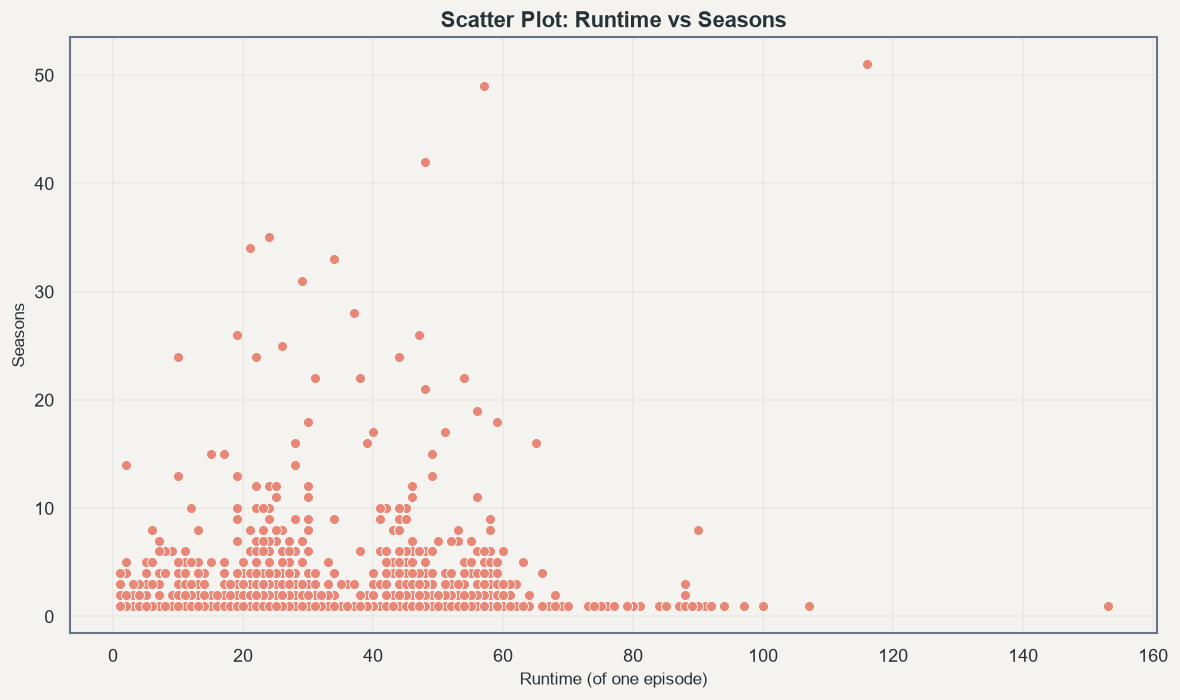

In [53]:
# Chart - 5 visualization code
plt.figure(figsize=(10,6))
sns.scatterplot(x='runtime',y='seasons',data=amazon_show2,color=PALETTE["coral"])
plt.xlabel('Runtime (of one episode)')
plt.ylabel('Seasons')
plt.title('Scatter Plot: Runtime vs Seasons')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


Scatter plot is used to compare two numerical features. This is used to compare the relationship between runtime and seasons.


##### 2. What is/are the insight(s) found from the chart?


The points are more clustered for Seasons 0-10, where the runtime is between 0 and 100. This suggests that most of the shows present here have less than 10 seasons. There are some shows whose seasons are in the range of 10-50 with runtime mostly between 0 and 60. There is one show with 50 seasons with a runtime of 120 and another show with one season and a runtime of approximately 158.


##### 3. Will the gained insights help create a positive business impact?



A scatter plot allows runtime and season count to be compared together, making clusters and unusual cases easier to spot. It helps describe the structure of TV shows and identify values that may need validation.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

The concentration of shows at lower season counts and runtimes describes the catalogue, but it does not establish that shorter shows generate more subscriptions. Very high season counts or unusual runtime values may need validation; they are data-quality or catalogue-review signals rather than evidence of negative growth.

#### Chart - 6


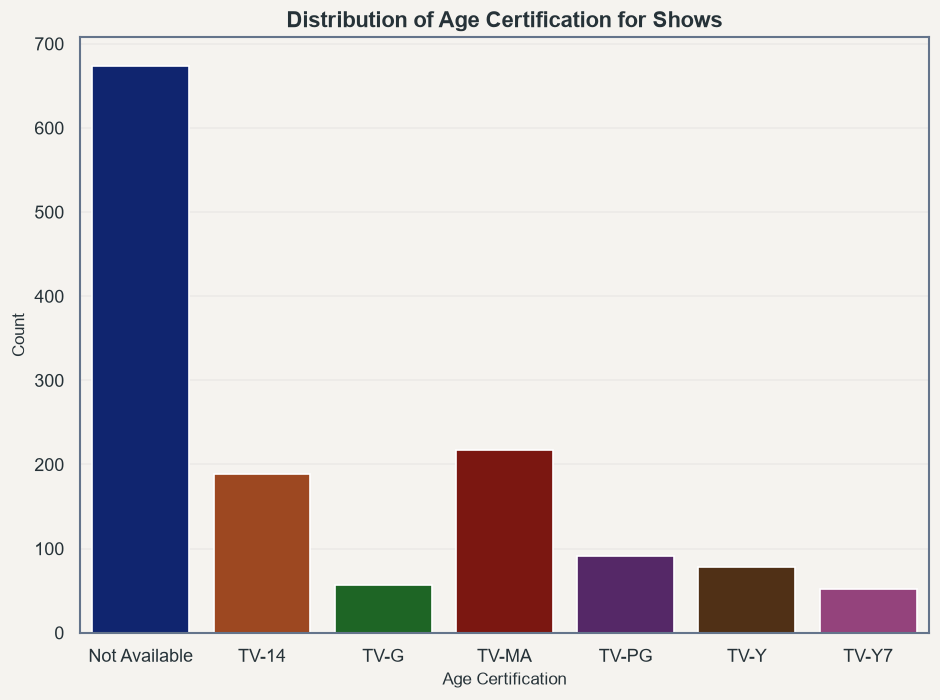

In [54]:
# Chart - 6 visualization code
# Distribution of Age certification for shows
amazon_show2 = md2[md2.type=='SHOW'].groupby('age_certification')['age_certification'].count()
amazon_show2 = pd.DataFrame(amazon_show2)
# Rename the count column
amazon_show2.rename(columns={'age_certification': 'count'}, inplace=True)
amazon_show2.reset_index(inplace=True)
# Create a bar plot
plt.figure(figsize=(8, 6))  # Adjust figure size
sns.barplot(data=amazon_show2, x="age_certification", y="count", hue="age_certification", palette="dark", legend=False)

# Rotate x-axis labels for better readability
#plt.xticks(rotation=45, ha="right")
plt.xlabel("Age Certification")
plt.ylabel("Count")
plt.title("Distribution of Age Certification for Shows")

# Show the plot
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To understand the age certification distribution for shows.


##### 2. What is/are the insight(s) found from the chart?


For most of the shows, age certification isn't available. Considering the ones that are available, majority of the shows fall in TV-MA category. The second highest is TV-14. Rest are quite less with TV-Y7 and TV-14 being the least. A decreasing trend is observed from TV-PG to TV-Y7.


##### 3. Will the gained insights help create a positive business impact?



A count chart of TV-show age certifications shows which audience-rating categories are represented and how much certification information is missing. This can help assess the catalogue's metadata completeness and broad content classification.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

A large 'unknown' or missing certification group can limit the usefulness of age-based catalogue analysis and may create a metadata-quality risk. It does not demonstrate negative growth. Improving metadata completeness and checking applicable regional classification rules could support better filtering and reporting.

#### Chart - 7


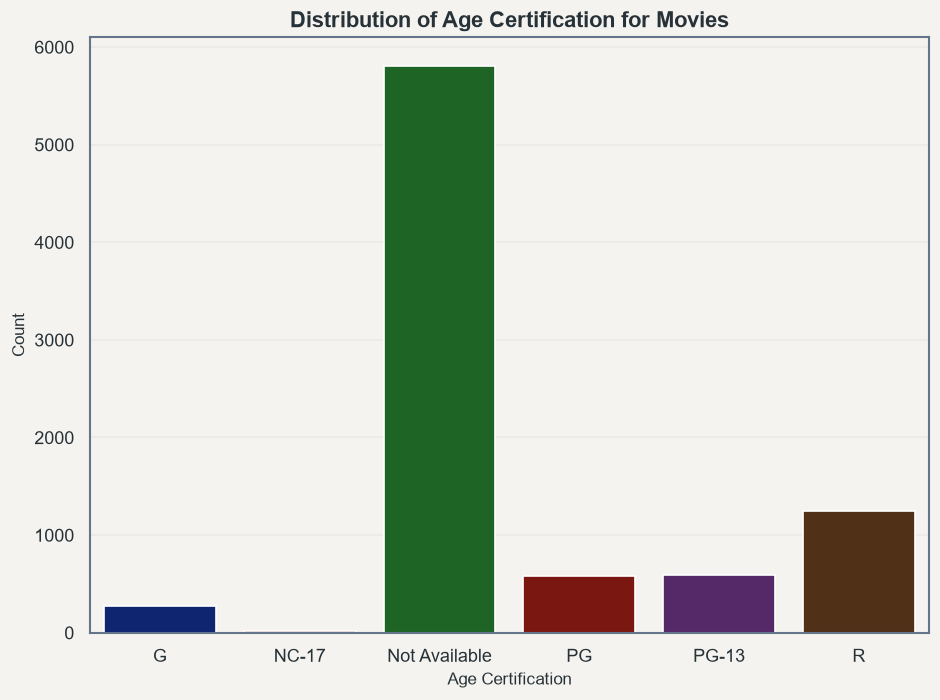

In [55]:
# Chart - 7 visualization code
# Distribution of Age certification for movie
amazon_movies2 = md2[md2.type=='MOVIE'].groupby('age_certification')['age_certification'].count()
amazon_movies2 = pd.DataFrame(amazon_movies2)
# Rename the count column
amazon_movies2.rename(columns={'age_certification': 'count'}, inplace=True)
amazon_movies2.reset_index(inplace=True)
# Create a bar plot
plt.figure(figsize=(8, 6))  # Adjust figure size
sns.barplot(data=amazon_movies2, x="age_certification", y="count", hue="age_certification", palette="dark", legend=False)

# Rotate x-axis labels for better readability
#plt.xticks(rotation=45, ha="right")
plt.xlabel("Age Certification")
plt.ylabel("Count")
plt.title("Distribution of Age Certification for Movies")

# Show the plot
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To understand the distribution of age certification for movies.


##### 2. What is/are the insight(s) found from the chart?


For majority of movies, the age certification isn't available. Out of the ones that are available, R category is the highest and NC-17 is the least. There are equal number of movies belonging to PG and PG-13 category and very less movies in G category.


##### 3. Will the gained insights help create a positive business impact?



The movie age-certification distribution helps describe the content-rating mix and whether certification data is available for most titles. This is useful for understanding catalogue classification and identifying missing metadata.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

If many movie ratings are unavailable, users and analysts may have less information for filtering or comparing titles. That is a potential usability and data-quality concern, not proof of declining business performance. Validate missing certifications and compare with customer usage before claiming an impact.

#### Chart - 8


In [56]:
amazon_prod = mdu.drop('genres',axis=1)
amazon_prod.duplicated().sum()

np.int64(14750)

In [57]:
amazon_prod.drop_duplicates(inplace=True)

In [58]:
amazon_prod.duplicated().sum()

np.int64(0)

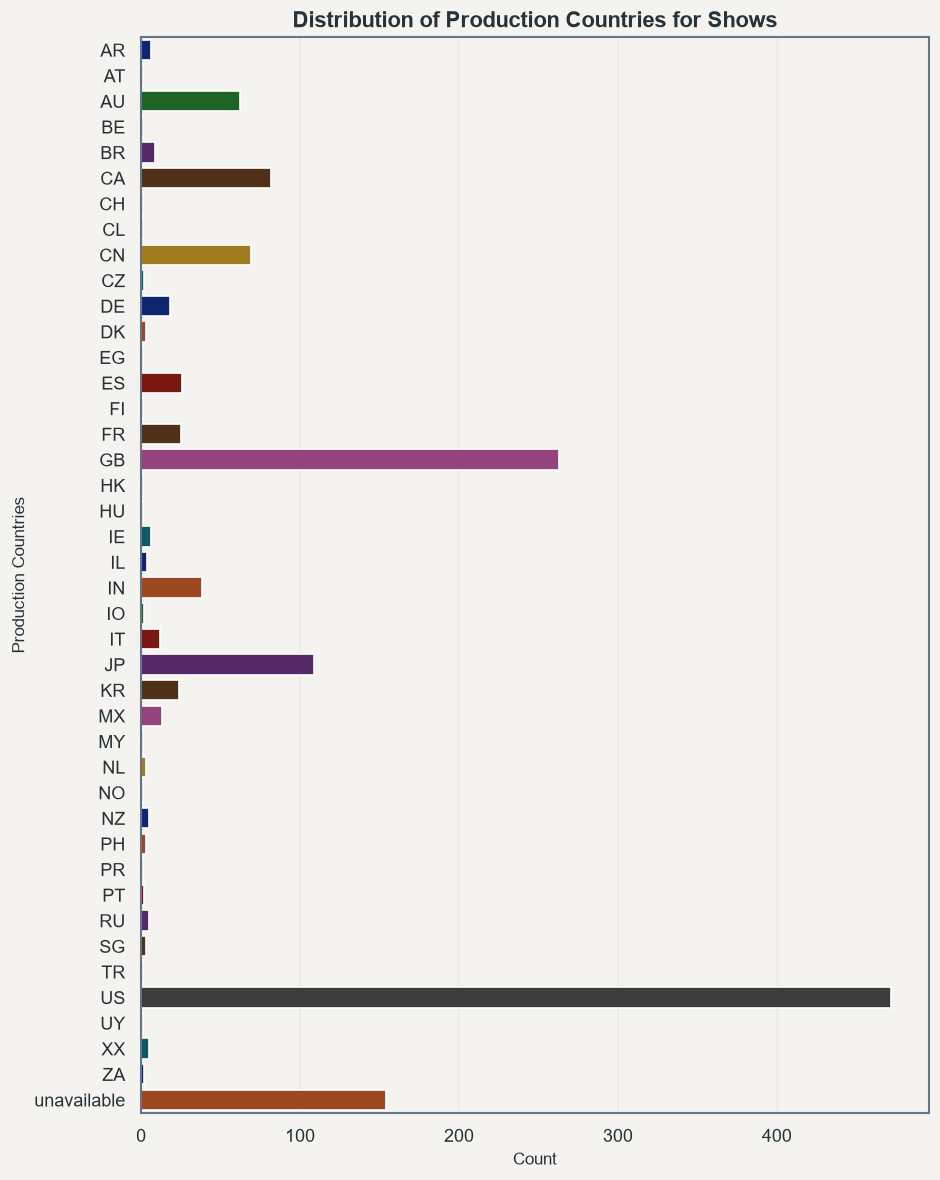

In [59]:
# Chart - 8 visualization code
# Distribution of production countries for shows
amazon_shows3 = amazon_prod[amazon_prod.type=='SHOW'].groupby('production_countries')['production_countries'].count()
amazon_shows3 = pd.DataFrame(amazon_shows3)
amazon_shows3.rename(columns={'production_countries':'count'},inplace=True)
amazon_shows3.reset_index(inplace=True)
# Create a bar plot
plt.figure(figsize=(8, 10))  # Adjust figure size
sns.barplot(data=amazon_shows3, x="count", y="production_countries", hue="production_countries", palette="dark", legend=False)

# Rotate x-axis labels for better readability
plt.ylabel("Production Countries")
plt.xlabel("Count")
plt.title("Distribution of Production Countries for Shows")

# Show the plot
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To analyse the distribution of production countries for shows.


##### 2. What is/are the insight(s) found from the chart?


United States have produced the highest number of shows on Amazon Prime. United Kingdom has also produced nearly 260 shows which is the second highest. For nearly 160 shows, the production country is unknown. Japan has produced more than 100 shows on Amazon Prime. Australia, Canada and China have produced a fairly good number of shows. Rest of the countries have produced have produced less number of shows.


##### 3. Will the gained insights help create a positive business impact?



The country distribution for TV shows highlights which production countries are most represented and where country metadata is missing. This helps describe the catalogue's geographic breadth and identify regions for closer review.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

A concentration of shows from a small number of countries and many unknown entries could indicate limited visible representation or incomplete metadata. Neither point proves weak demand or negative growth in other countries; regional viewing, language preferences, licensing availability, and metadata completeness should be checked.

#### Chart - 9


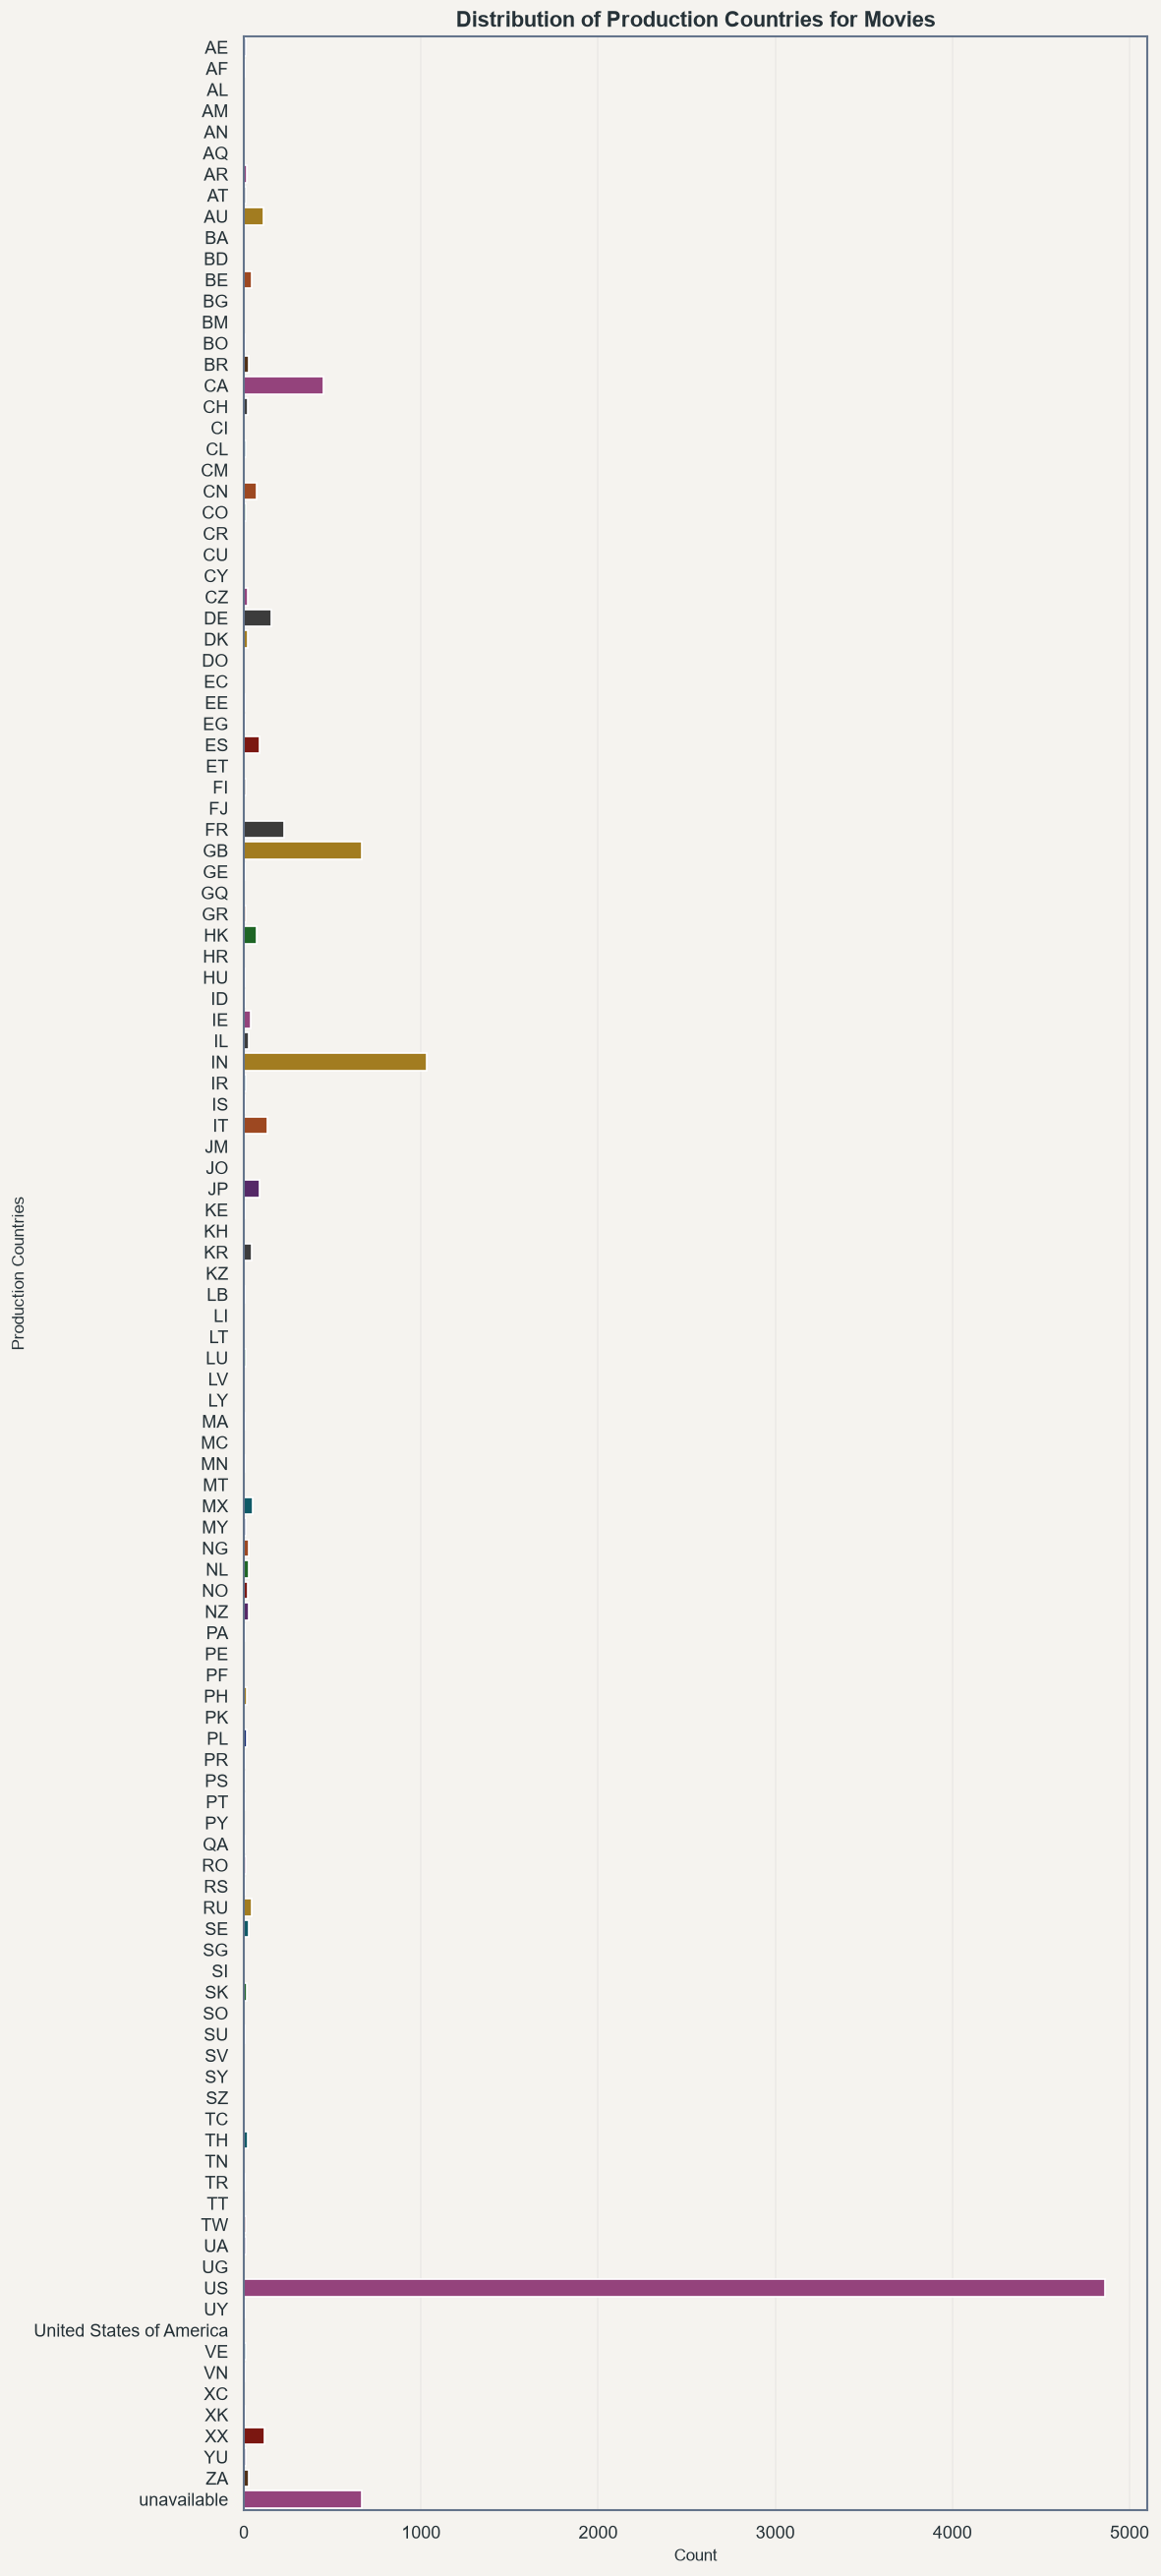

In [60]:
# Chart - 9 visualization code
# Distribution of production countries for movies
amazon_movies3 = amazon_prod[amazon_prod.type=='MOVIE'].groupby('production_countries')['production_countries'].count()
amazon_movies3 = pd.DataFrame(amazon_movies3)
amazon_movies3.rename(columns={'production_countries':'count'},inplace=True)
amazon_movies3.reset_index(inplace=True)
# Create a bar plot
plt.figure(figsize=(10, 22))  # Adjust figure size
sns.barplot(data=amazon_movies3, x="count", y="production_countries", hue="production_countries", palette="dark", legend=False)

# Rotate x-axis labels for better readability
plt.ylabel("Production Countries")
plt.xlabel("Count")
plt.title("Distribution of Production Countries for Movies")

# Show the plot
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To analyse the distribution of production countries for movies.


##### 2. What is/are the insight(s) found from the chart?


Majority of the movies are produced by the United States. However, the second highest is India and not UK unlike for shows. For nearly 800 movies, the production countries are unknown. Canada, France and UK have produced a fairly good number of movies. Rest of the countries have produced produced less number of movies.


##### 3. Will the gained insights help create a positive business impact?



The movie production-country chart makes it possible to compare the countries most represented in the catalogue and identify missing country information. It provides a starting point for reviewing geographic diversity.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

Lower movie counts for some countries may indicate less catalogue representation, but they do not establish low subscription potential or negative growth. Any expansion decision should consider regional audience data, language and cultural fit, rights availability, and acquisition costs.

#### Chart - 10


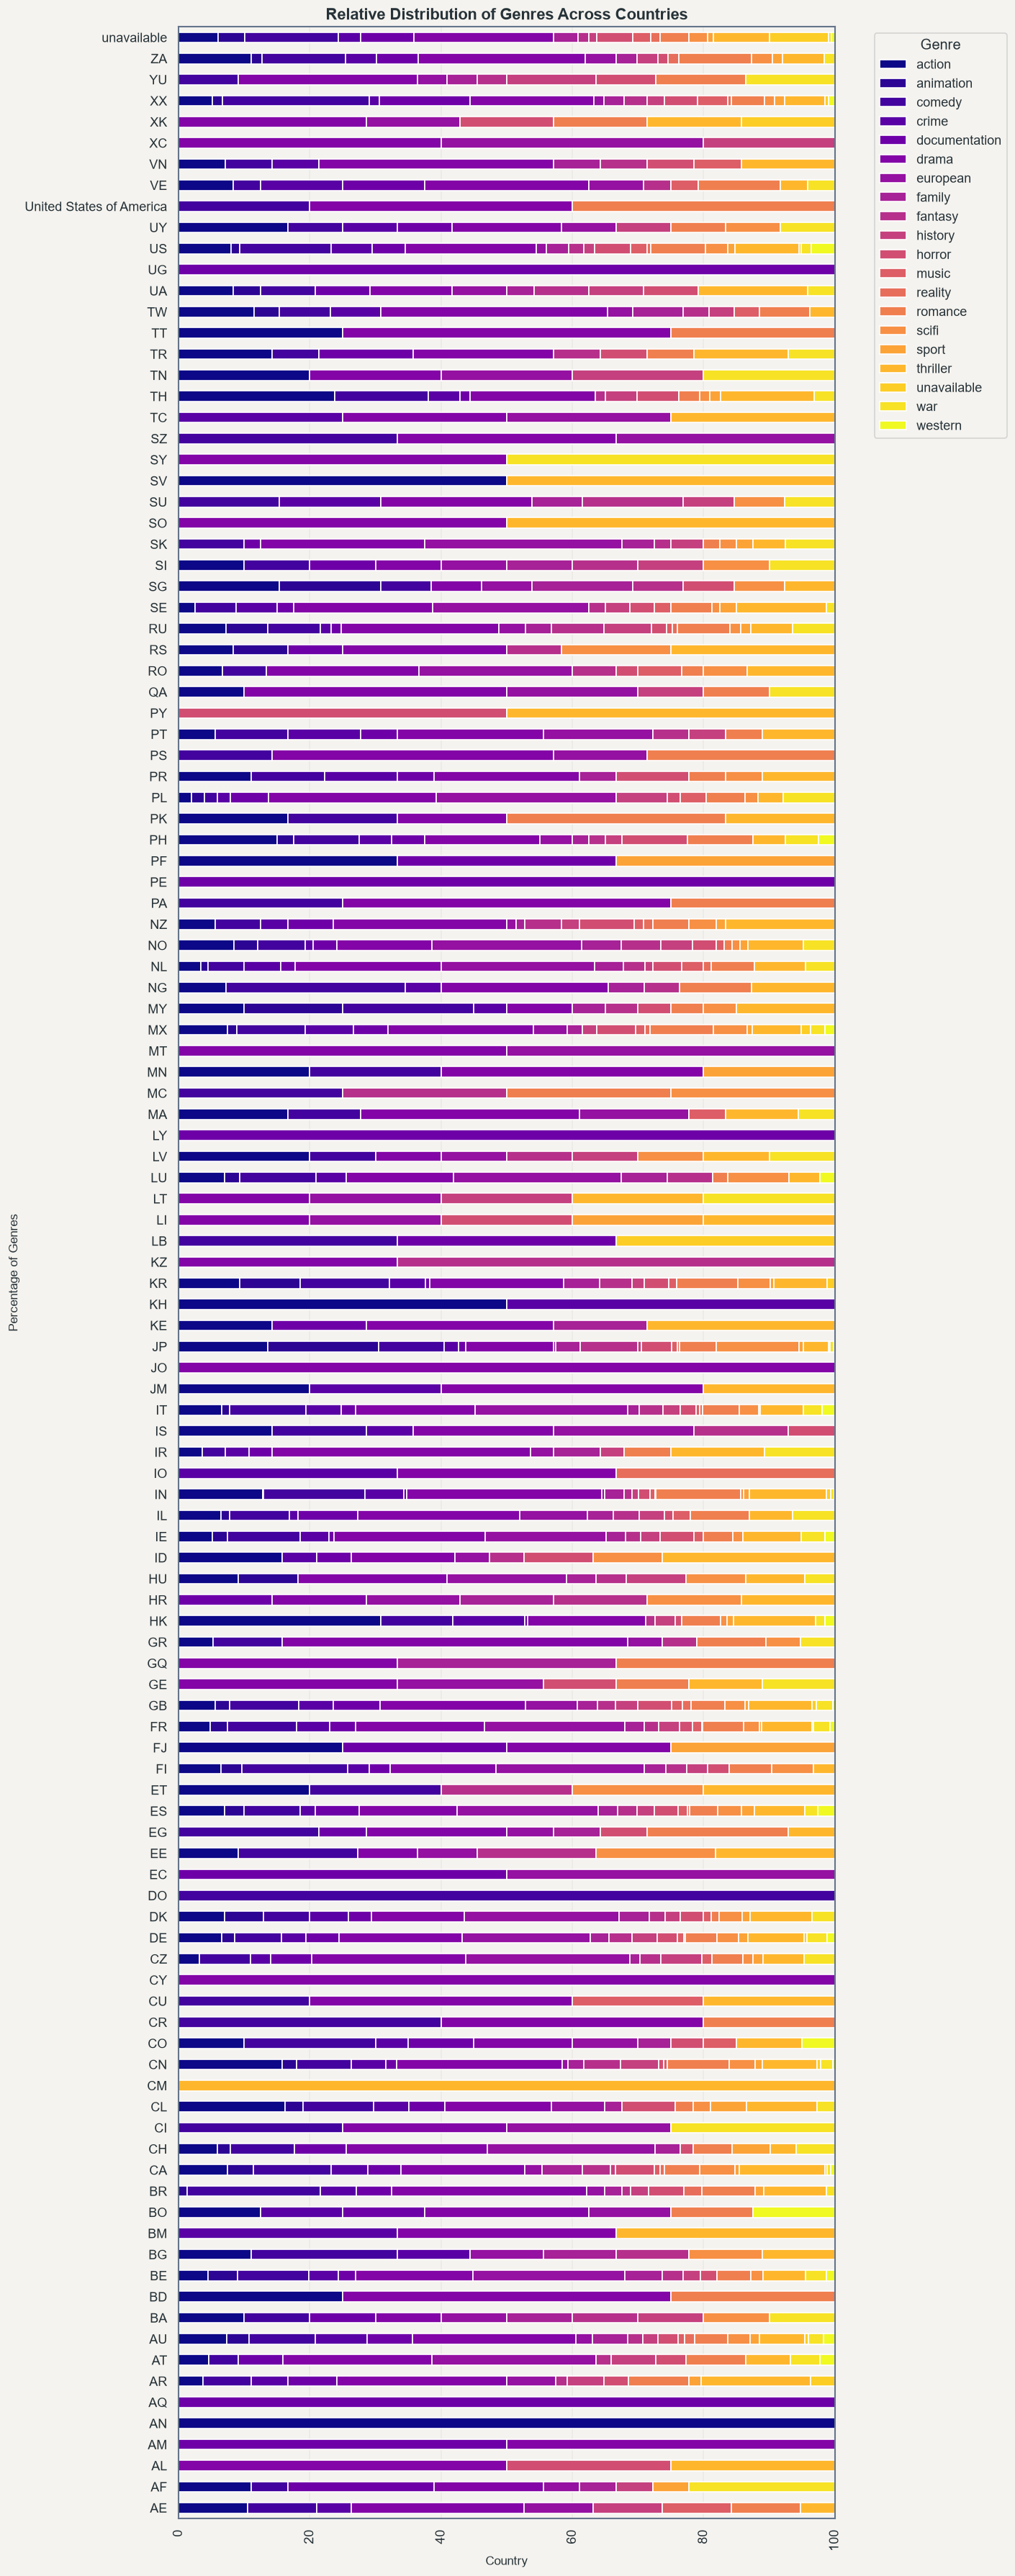

In [61]:
# Chart - 10 visualization code
# Convert groupby Series to DataFrame and reset index
df_counts = mdu.groupby(["production_countries", "genres"]).size().unstack(fill_value=0)
df_relative = df_counts.div(df_counts.sum(axis=1), axis=0) * 100
# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(12, 30))
df_relative.plot(kind="barh", stacked=True, colormap="plasma", ax=ax)

# Labels and title
plt.xlabel("Country")
plt.ylabel("Percentage of Genres")
plt.title("Relative Distribution of Genres Across Countries")
plt.legend(title="Genre", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=90)  # Rotate country names for readability

plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


Relative stacked bar plot is useful in under relative distribution of genres across countries.


##### 2. What is/are the insight(s) found from the chart?


Most of the countries have a fair distribution across different genres which means there is a diverse production of films and shows and there are more audiences who prefer diverse genres and also resources for producing multiple films or shows in a year. However, if we observe in countries like Cameroon, Cambodia, Antartica, Armenia, Peru, Paraguay, Uganda, Syria, Jordan, Cyprus, Dominican Republic and Kazakastan, there is no fair distribution of all genres. There are only like 1 or 2 genres in each bar. This means that in these countries films or shows produced are quite less and either there aren't much people who prefer movies/shows or they prefer other streaming platforms over Amazon Prime.


##### 3. Will the gained insights help create a positive business impact?



A relative stacked bar chart compares the proportional genre mix across production countries, making differences in catalogue composition easier to see even when countries have different total title counts.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

Countries with only one or two represented genres may have limited catalogue breadth in this dataset, but this could also reflect small sample sizes or incomplete metadata. It is not evidence that people in those countries prefer other platforms. Regional viewing and subscription data would be required to assess a real business risk.

#### Chart - 11


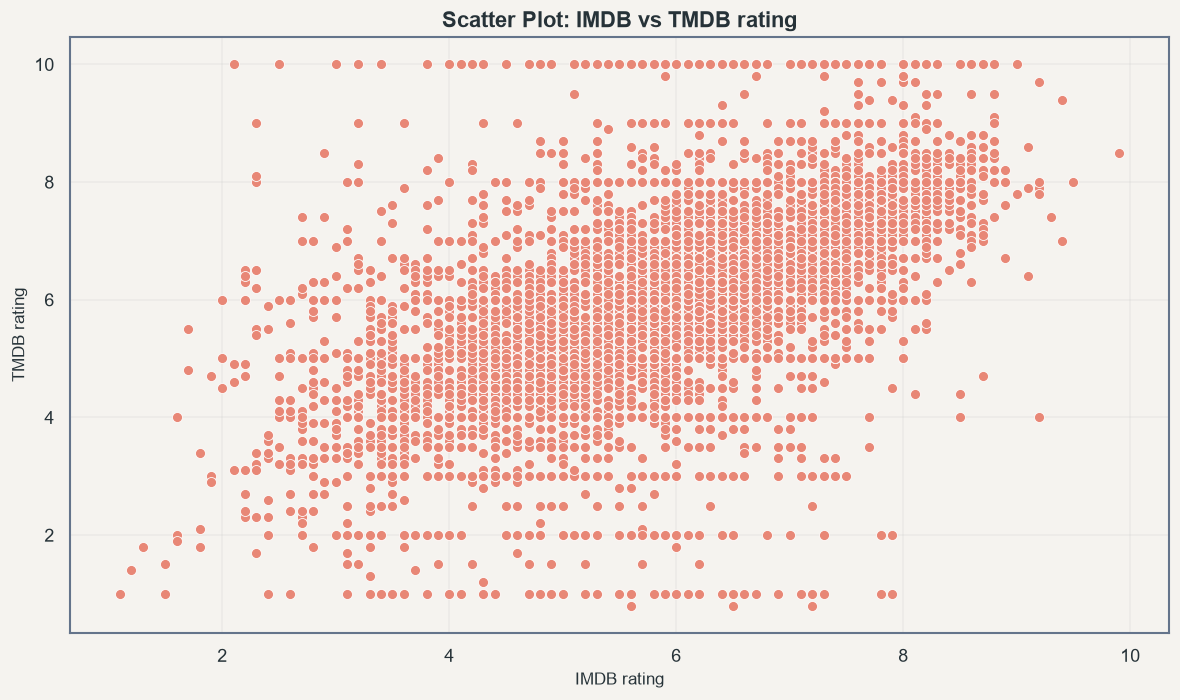

In [62]:
# Chart - 11 visualization code
# scatterplot imdb_score vs tmdb_score
plt.figure(figsize=(10,6))
sns.scatterplot(x='imdb_score',y='tmdb_score',data=md2,color=PALETTE["coral"])
plt.xlabel('IMDB rating')
plt.ylabel('TMDB rating')
plt.title('Scatter Plot: IMDB vs TMDB rating')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To compare IMDB rating and TMDB rating given for the corresponding shows and movies. Scatter plot is used to compare two numerical features.


##### 2. What is/are the insight(s) found from the chart?


A positive correlation is observed from the chart. However there are some datapoints for which IMDB is 0 but TMDB is from 0 to 10 and vice versa. This is because, some of the null values have been replaced with zero.


##### 3. Will the gained insights help create a positive business impact?



The scatter plot compares IMDb and TMDb scores to see whether the two rating measures tend to move together and to identify unusual or potentially invalid values.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

A positive relationship between the scores may help identify titles whose ratings are consistent across sources. Zero values can distort the pattern if they stand for missing scores, so they should be treated as a data-quality limitation. The chart does not show that ratings cause subscription growth or decline.

#### Chart - 12


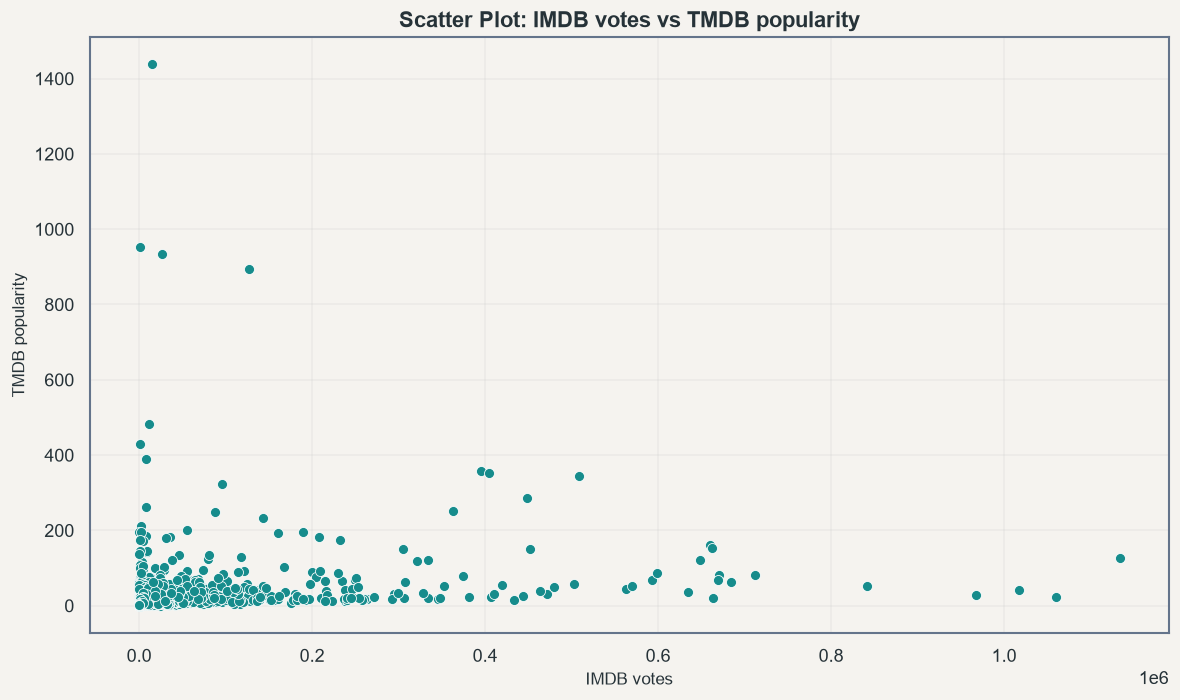

In [63]:
# Chart - 12 visualization code
# scatter plot of imdb_votes and tmdb_popularity
plt.figure(figsize=(10,6))
sns.scatterplot(x='imdb_votes',y='tmdb_popularity',data=md2,color=PALETTE["teal"])
plt.xlabel('IMDB votes')
plt.ylabel('TMDB popularity')
plt.title('Scatter Plot: IMDB votes vs TMDB popularity')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To compare the relationship between IMDB votes and TMDB popularity.


##### 2. What is/are the insight(s) found from the chart?


There are more points clustered where IMDB votes lie between (0-0.4)x1e6 and TMDB popularity lying between 0 and 200. Also, for most of the points, TMDB popularity lies between 0 and 200. There are 3 points for which IMDB is less and TMDB is quite high. This suggests that TMDB popularity is less and around 200 for most of the movies and shows even though IMDB votes are high for some shows.


##### 3. Will the gained insights help create a positive business impact?



The scatter plot compares IMDb vote counts with TMDb popularity, allowing the analysis to inspect whether titles with more votes also tend to have higher popularity scores and to spot outliers.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

The chart shows that many titles sit in lower vote-count and popularity ranges, with some outliers. These metrics are not direct measures of Prime Video viewing or subscription behaviour, and missing values may affect the relationship. No negative growth can be concluded without platform engagement and business metrics.

#### Chart - 13


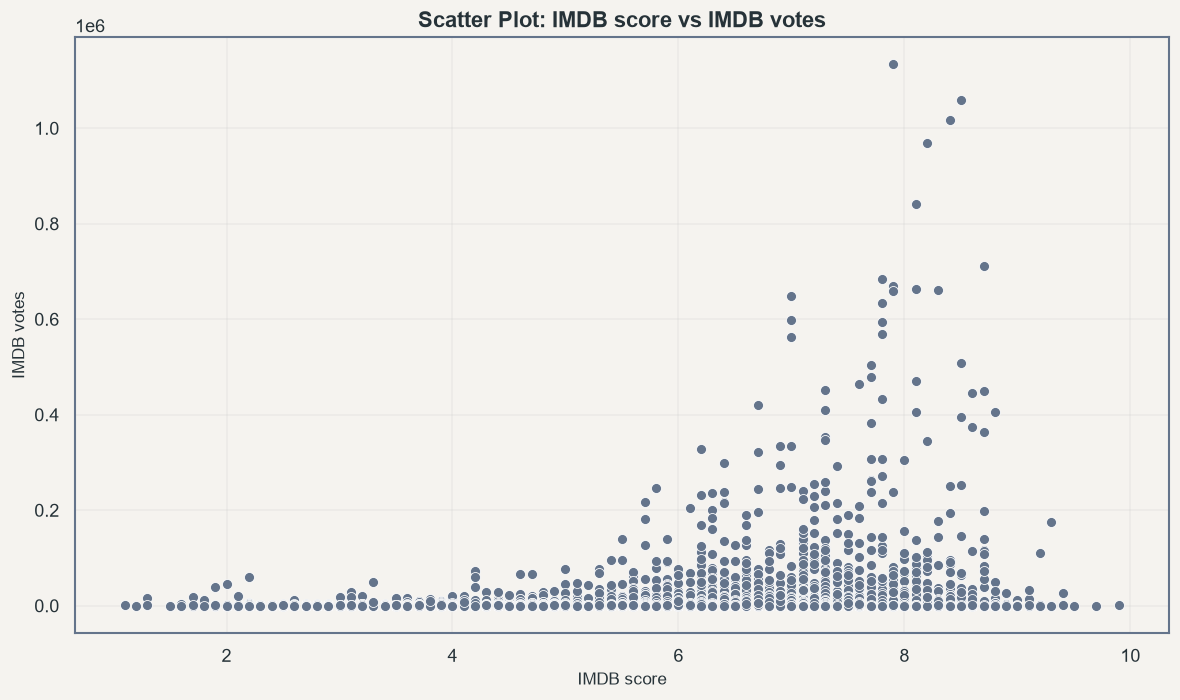

In [64]:
# Chart - 13 visualization code
# scatter plot of imdb_score and imdb_votes
plt.figure(figsize=(10,6))
sns.scatterplot(x='imdb_score',y='imdb_votes',data=md2,color=PALETTE["slate"])
plt.xlabel('IMDB score')
plt.ylabel('IMDB votes')
plt.title('Scatter Plot: IMDB score vs IMDB votes')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


To make a comparison between IMDB score and IMDB votes.


##### 2. What is/are the insight(s) found from the chart?


The points are clustered in the regions where IMDB votes are in the range of 0-400000. For some movies where the IMDB score is between 6 and 8, the IMDB votes are quite high.


##### 3. Will the gained insights help create a positive business impact?



Comparing IMDb scores with IMDb vote counts helps show how rating values are distributed across titles with different levels of rating participation and whether highly rated titles also have many votes.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

Some titles with scores in the mid-to-high range have large vote counts, but votes and ratings come from an external metadata source and do not directly measure Prime Video usage. Low vote counts may mean limited external rating activity, not poor performance. Use internal viewing and retention data before making content-investment decisions.

#### Chart - 14 - Correlation Heatmap


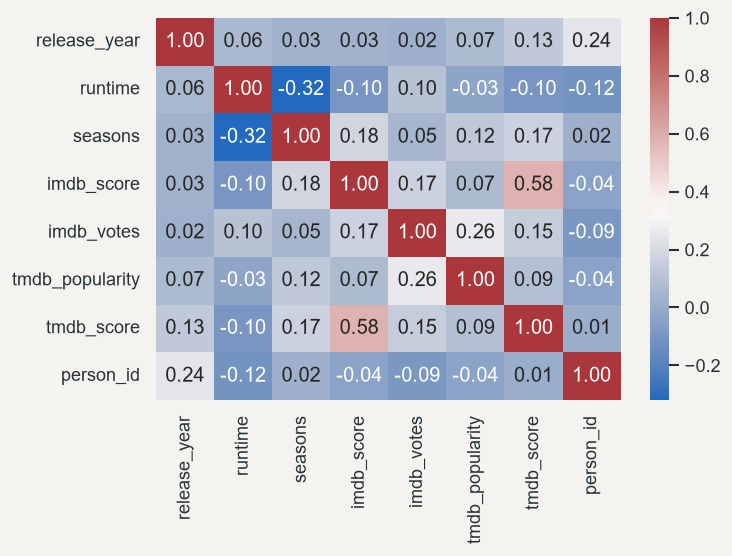

In [65]:
# Correlation Heatmap visualization code
amazon_tit_num = md2.select_dtypes(include='number')
corr_mat = amazon_tit_num.corr()
sns.heatmap(corr_mat,annot=True,cmap="vlag", fmt=".2f")
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?


Correlation matrix is used to compare numerical features in the dataset.


##### 2. What is/are the insight(s) found from the chart?


There is quite stronger negative correlation between runtime and seasons. There is a stronger positive correlation between imdb_score and tmdb_score, and likewise imdb_votes and tmdb_popularity.


#### Chart - 15 - Pair Plot


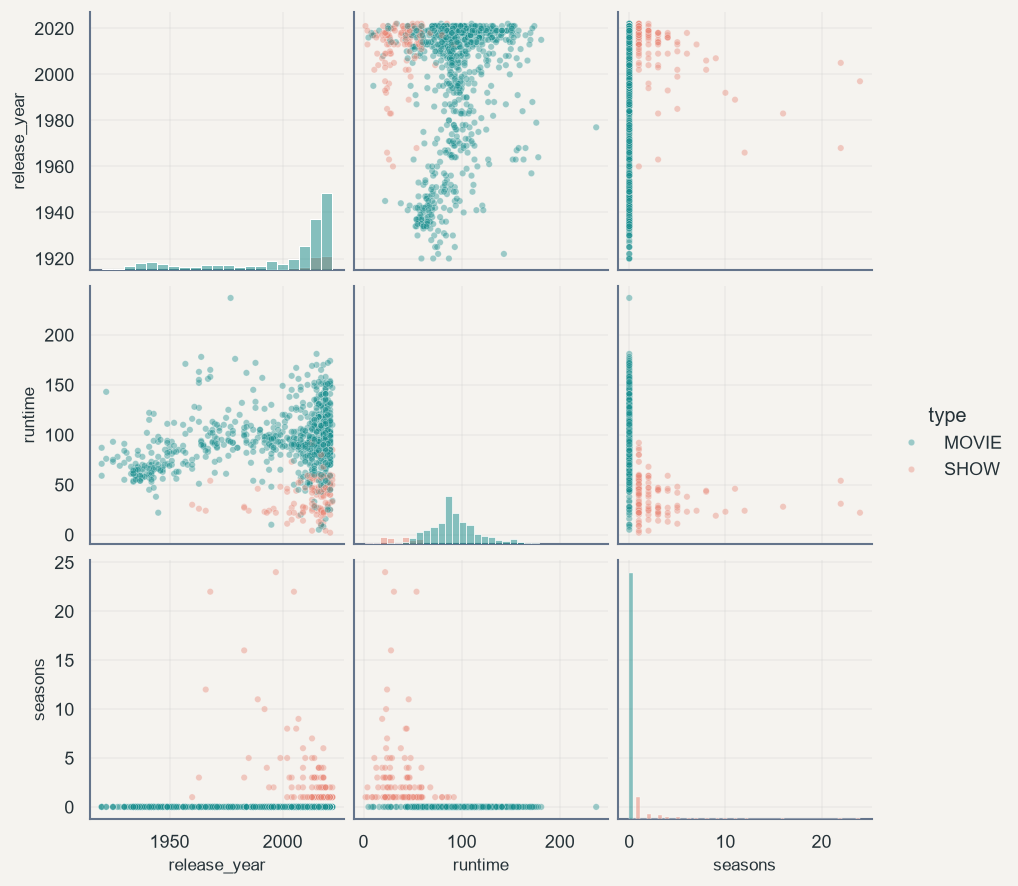

In [66]:

# Select a small number of numeric columns
numeric_cols = md2.select_dtypes(include='number').columns[:3]

amazon_tit_up = md2[list(numeric_cols)].copy()
amazon_tit_up['type'] = md2['type']

# Use a sample if the dataset is large
if len(amazon_tit_up) > 1000:
    amazon_tit_up = amazon_tit_up.sample(
        n=1000, random_state=42
    )

sns.pairplot(
    amazon_tit_up,
    hue='type',
    palette=TYPE_PALETTE,
    diag_kind='hist',
    plot_kws={'alpha': 0.4, 's': 15}
)

plt.show()


##### 1. Why did you pick the specific chart?


To compare the numerical features based on type 'show' and 'movie'.


##### 2. What is/are the insight(s) found from the chart?


Some features could possibly have liner or non-linear relationships and random scatter between some features suggest that there is no correlation. IMDb score and TMDb score have a similar distribution as the KDE plot for both are quite similar. Runtime, seasons, IMDb votes and TMDb popularity are positively skewed. Some movies seem to dominate in votes and popularity. Some points are far from the main clusters, indicating highly popular movies/shows or exceptions in runtime/seasons. Movies might have higher IMDb votes and popularity, while shows could have wider variability in scores.

##### 3. Will the gained insights help create a positive business impact?

A pair plot compares distributions and pairwise relationships among numerical fields, with separate patterns by content type. It helps reveal clustering, skew, and outliers that may be less obvious in a single chart.

##### Are there any insights that lead to negative growth? Justify with specific reasons.

The plots show skewed distributions and some outliers, while IMDb and TMDb scores appear to have similar patterns. These findings can guide data validation and further analysis, but external ratings and popularity are not the same as platform viewership. Unusual values or differences between movies and shows are investigation points, not evidence of negative growth.

## **5. Solution to Business Objective**


The findings suggest several practical next steps:

1. Review the balance of genres and content types alongside internal viewing and completion data before deciding where to acquire more titles.
2. Investigate the apparent decline in recent release-year counts after confirming that the dataset covers those years consistently and distinguishing release dates from platform additions or removals.
3. Improve completeness of production-country and age-certification metadata so catalogue comparisons and filtering are more reliable.
4. Recalculate rating relationships after handling missing numerical values without treating missing scores as genuine zeros.
5. Combine catalogue analysis with regional viewership, engagement, retention, licensing costs, and revenue before evaluating whether a content strategy has a positive or negative business impact.

These recommendations are evidence-led follow-up actions; the current dataset does not establish which content choices will increase subscriptions.

1) Most of the genre comprises of drama and comedy. However crime, thriller, animation, action and sci-fi shows and movies are quite less. Including more shows in this genre can actually increase the number of subscribers.

2) Including shows with lesser runtime for each episode can cater a huge audience.

3) Based on the data presented in the relative stacked bar plot, once can tailor user based preferences to include more shows and movies in the preferred genre.

4) Including shows and films with higher IMDB and TMDB rating would bring in more subscribers.


# **Conclusion**


The analysis describes the Amazon Prime Video catalogue across content types, genres, release years, production countries, age certifications, runtime, and selected IMDb/TMDb measures. Drama and comedy are strongly represented in the genre breakdowns, the United States appears prominently among production countries, and the release-year charts show substantial growth in catalogue titles after earlier years followed by lower counts in the most recent years shown. The runtime, season, and rating plots also reveal clusters, skewed distributions, and some outlying values.

The findings should be interpreted with care. Missing country and certification values limit some comparisons, and replacing missing numerical ratings or popularity values with zero can affect distributions and correlations. Genre and country fields may contain multiple labels per title, so category counts are not necessarily unique-title totals. Most importantly, this dataset describes catalogue metadata, not actual Prime Video viewing, subscription, retention, or revenue outcomes. Further analysis using internal engagement and financial data is needed before concluding that any observed pattern will produce positive impact or negative growth.